# Proyecto final de Machine Learning — Rossmann Store Sales
**Predicción de ventas diarias por establecimiento con Random Forest y XGBoost**  
**Etapa 1: Introducción, integración y análisis exploratorio (EDA)**

> Este notebook es la primera etapa del proyecto. Los modelos, optimización, comparación estadística y t-SNE se incorporarán después de revisar el EDA. Los resultados deben ejecutarse en Colab; no se presentan métricas inventadas.

## 1. Introducción
La planificación de ventas permite anticipar necesidades operativas y comerciales en establecimientos minoristas. Factores como promociones, calendarios festivos, competencia y características de las tiendas pueden relacionarse con las ventas observadas. El dataset Rossmann Store Sales proporciona registros históricos diarios por tienda, adecuados para explorar estas relaciones y construir modelos predictivos.

**Problema:** estimar las ventas diarias (`Sales`) de cada tienda utilizando información disponible antes del día de predicción. No se usará `Customers`, pues corresponde a una cantidad observada el mismo día y no conocida anticipadamente.

**Objetivo general:** desarrollar y comparar modelos de Random Forest y XGBoost para estimar ventas diarias por establecimiento.

**Objetivos específicos:** (1) analizar calidad y patrones de datos; (2) construir preprocesamiento y selección de variables en pipelines; (3) optimizar hiperparámetros; (4) comparar modelos estadísticamente; (5) interpretar resultados y limitaciones.

**Precaución metodológica:** como los registros tienen estructura temporal, el rendimiento futuro se evaluará con particiones cronológicas. La exigencia de *Repeated K-Fold* de la rúbrica se analizará como experimento académico complementario, evitando presentar sus resultados como estimaciones realistas de pronóstico futuro.


## 2. Cargar archivos

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google.colab import files

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "ctoa99/Proyecto-ML-chtoapantam-MSDS/main/"
)

train = pd.read_parquet(BASE_URL + "train.parquet")
stores = pd.read_csv(BASE_URL + "store.csv")

print("Ventas:", train.shape)
print("Tiendas:", stores.shape)


Ventas: (1017209, 9)
Tiendas: (1115, 10)


## 3. Integración y validación de tablas

In [7]:
assert train['Store'].notna().all()
assert stores['Store'].is_unique
assert train[['Store','Date']].duplicated().sum() == 0

df = train.merge(stores, on='Store', how='left', validate='many_to_one', indicator=True)
print('Coincidencia de tiendas:')
print(df['_merge'].value_counts())
assert (df['_merge'] == 'both').all()
df = df.drop(columns='_merge')
print('Dimensiones:', df.shape)
print('Fechas:', df.Date.min().date(), 'a', df.Date.max().date())
print('Tiendas:', df.Store.nunique())
display(df.head())

Coincidencia de tiendas:
_merge
both          1017209
left_only           0
right_only          0
Name: count, dtype: int64
Dimensiones: (1017209, 18)
Fechas: 2013-01-01 a 2015-07-31
Tiendas: 1115


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


El período analizado comprende desde el 1 de enero de 2013 hasta el 31 de julio de 2015.

Las variables asociadas con promociones secundarias y fechas de apertura de competidores concentran la mayor proporción de datos faltantes.

No recomiendo eliminar las filas con valores nulos, porque perderíamos una cantidad considerable de información. En su lugar, podemos utilizar imputación dentro de los pipelines y crear indicadores de ausencia cuando resulte pertinente.

También debemos considerar que algunas ausencias pueden ser estructurales. Por ejemplo, una tienda sin *Promo2* puede no tener una fecha de inicio de esa promoción.

## 4. Calidad de datos y estadísticas descriptivas

In [8]:
missing = pd.DataFrame({'n_faltantes': df.isna().sum(), 'porcentaje': (df.isna().mean()*100).round(2)})
display(missing[missing.n_faltantes > 0].sort_values('n_faltantes', ascending=False))
print('Duplicados tienda-fecha:', df.duplicated(['Store','Date']).sum())
print('Días cerrados:', (df.Open == 0).sum())
print('Ventas cero:', (df.Sales == 0).sum())
print('Ventas cero con tienda abierta:', ((df.Sales == 0) & (df.Open == 1)).sum())
display(df[['Sales','Customers','CompetitionDistance']].describe())

,n_faltantes,porcentaje
Promo2SinceYear,508031,49.94
Promo2SinceWeek,508031,49.94
PromoInterval,508031,49.94
CompetitionOpenSinceMonth,323348,31.79
CompetitionOpenSinceYear,323348,31.79
CompetitionDistance,2642,0.26


Duplicados tienda-fecha: 0
Días cerrados: 172817
Ventas cero: 172871
Ventas cero con tienda abierta: 54


,Sales,Customers,CompetitionDistance
count,1.017209e+06,1.017209e+06,1.014567e+06
mean,5.773819e+03,6.331459e+02,5.430086e+03
std,3.849926e+03,4.644117e+02,7.715324e+03
min,0.000000e+00,0.000000e+00,2.000000e+01
25%,3.727000e+03,4.050000e+02,7.100000e+02
50%,5.744000e+03,6.090000e+02,2.330000e+03
75%,7.856000e+03,8.370000e+02,6.890000e+03
max,4.155100e+04,7.388000e+03,7.586000e+04


El promedio de ventas considera tanto días abiertos como cerrados. Para estudiar la demanda comercial, es más representativo analizar las observaciones correspondientes a tiendas abiertas.

## 5. Ingeniería de variables para el EDA
Estas variables se derivan de la fecha conocida antes de la predicción. Las transformaciones que aprendan parámetros de los datos se ajustarán **dentro de los pipelines** en la etapa de modelado.

In [9]:
df['Year'] = df.Date.dt.year
df['Month'] = df.Date.dt.month
df['WeekOfYear'] = df.Date.dt.isocalendar().week.astype(int)
df['DayOfMonth'] = df.Date.dt.day

a = df.loc[df.Open == 1].copy()
print('Observaciones con tienda abierta:', len(a))

Observaciones con tienda abierta: 844392


## 6. Visualizaciones exploratorias

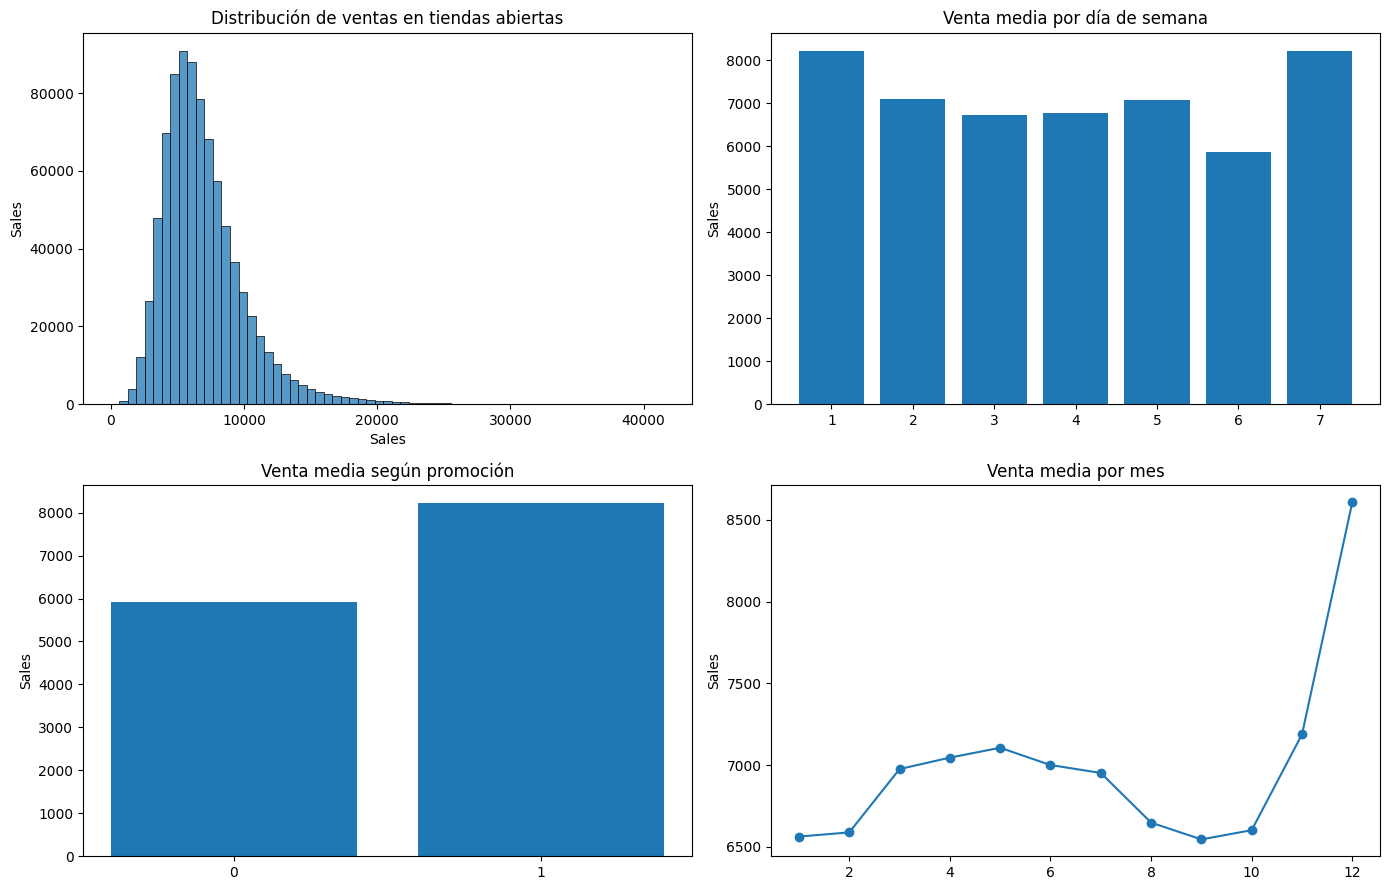

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(a['Sales'], bins=65, ax=axes[0,0]); axes[0,0].set_title('Distribución de ventas en tiendas abiertas')
by_day = a.groupby('DayOfWeek')['Sales'].mean()
axes[0,1].bar(by_day.index.astype(str), by_day.values); axes[0,1].set_title('Venta media por día de semana')
by_promo = a.groupby('Promo')['Sales'].mean()
axes[1,0].bar(by_promo.index.astype(str), by_promo.values); axes[1,0].set_title('Venta media según promoción')
by_month = a.groupby('Month')['Sales'].mean()
axes[1,1].plot(by_month.index, by_month.values, marker='o'); axes[1,1].set_title('Venta media por mes')
for ax in axes.flat: ax.set_ylabel('Sales')
plt.tight_layout(); plt.show()

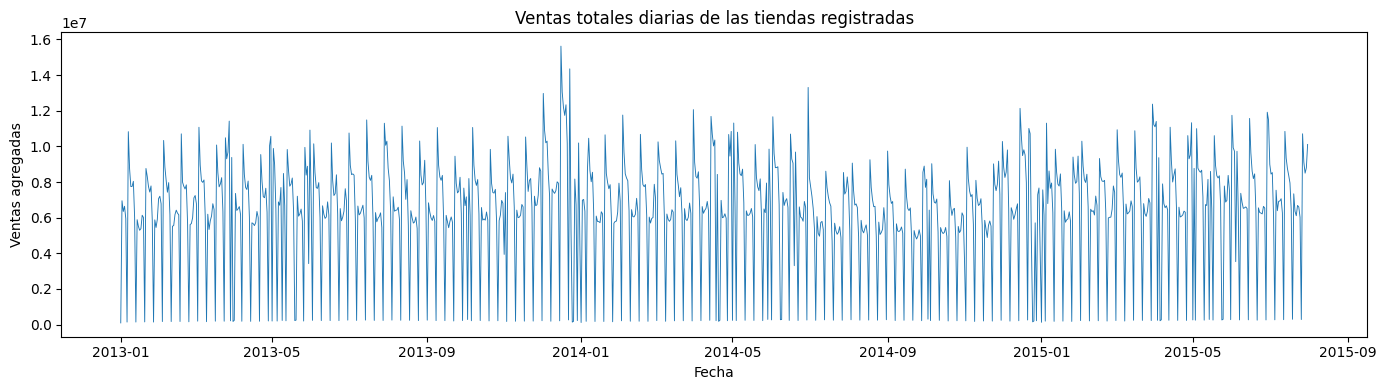

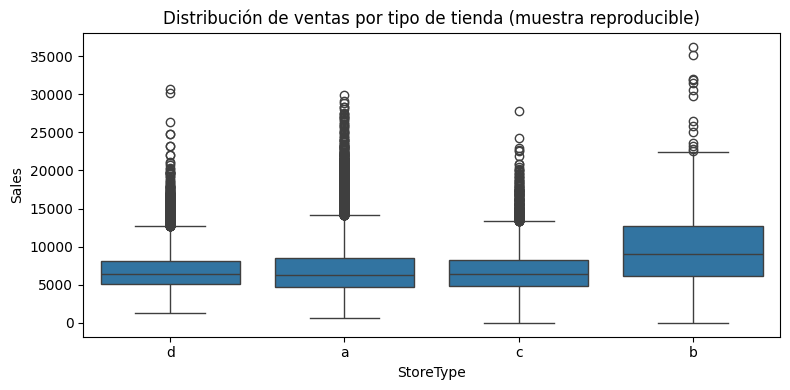

In [11]:
daily = df.groupby('Date', as_index=False)['Sales'].sum().sort_values('Date')
plt.figure(figsize=(14,4))
plt.plot(daily.Date, daily.Sales, linewidth=0.65)
plt.title('Ventas totales diarias de las tiendas registradas')
plt.xlabel('Fecha'); plt.ylabel('Ventas agregadas')
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
sns.boxplot(data=a.sample(n=min(40000,len(a)),random_state=42), x='StoreType', y='Sales')
plt.title('Distribución de ventas por tipo de tienda (muestra reproducible)')
plt.tight_layout(); plt.show()

El análisis exploratorio del dataset Rossmann Store Sales permitió identificar patrones relevantes en el comportamiento de las ventas de 1.115 establecimientos comerciales durante el período comprendido entre enero de 2013 y julio de 2015.

La integración de los conjuntos de datos de ventas y características de establecimientos produjo 1.017.209 observaciones y 18 variables, sin pérdidas de registros ni duplicados por combinación de tienda y fecha.

Se identificaron valores faltantes principalmente en variables relacionadas con promociones secundarias y apertura de establecimientos competidores. Estas ausencias requieren un tratamiento diferenciado, considerando tanto su significado comercial como la prevención de fugas de información durante el entrenamiento.

La distribución de ventas de las tiendas abiertas presenta asimetría positiva, con una concentración de observaciones en valores moderados y una cola correspondiente a ventas elevadas.

El análisis por día de la semana, mes y tipo de establecimiento evidenció diferencias en los niveles de ventas, lo que sugiere que las características temporales y operativas podrían aportar capacidad predictiva.

Asimismo, los establecimientos con promociones activas presentaron mayores ventas medias que aquellos sin promociones. Esta asociación respalda la inclusión de variables promocionales en los modelos, sin que ello implique establecer una relación causal.

En conjunto, los hallazgos justifican evaluar algoritmos capaces de representar relaciones no lineales e interacciones entre características, como Random Forest y XGBoost.

Finalmente, debido a la naturaleza cronológica de los datos, será necesario implementar una estrategia de validación que permita evaluar la generalización de los modelos hacia períodos futuros.

## 7. Interpretación

El análisis exploratorio del dataset Rossmann Store Sales permitió identificar patrones relevantes en el comportamiento de las ventas de 1.115 establecimientos comerciales durante el período comprendido entre enero de 2013 y julio de 2015.

La integración de los conjuntos de datos de ventas y características de establecimientos produjo 1.017.209 observaciones y 18 variables, sin pérdidas de registros ni duplicados por combinación de tienda y fecha.

Se identificaron valores faltantes principalmente en variables relacionadas con promociones secundarias y apertura de establecimientos competidores. Estas ausencias requieren un tratamiento diferenciado, considerando tanto su significado comercial como la prevención de fugas de información durante el entrenamiento.

La distribución de ventas de las tiendas abiertas presenta asimetría positiva, con una concentración de observaciones en valores moderados y una cola correspondiente a ventas elevadas.

El análisis por día de la semana, mes y tipo de establecimiento evidenció diferencias en los niveles de ventas, lo que sugiere que las características temporales y operativas podrían aportar capacidad predictiva.

Asimismo, los establecimientos con promociones activas presentaron mayores ventas medias que aquellos sin promociones. Esta asociación respalda la inclusión de variables promocionales en los modelos, sin que ello implique establecer una relación causal.

En conjunto, los hallazgos justifican evaluar algoritmos capaces de representar relaciones no lineales e interacciones entre características, como Random Forest y XGBoost.

Finalmente, debido a la naturaleza cronológica de los datos, será necesario implementar una estrategia de validación que permita evaluar la generalización de los modelos hacia períodos futuros.

**Decisiones preliminares:**
- `Sales` es la variable objetivo.
- `Customers` se excluirá de las variables predictoras.
- Se evaluará el efecto de `Open` y el tratamiento de los días cerrados de manera explícita.
- Los valores ausentes en `Promo2Since*` y `PromoInterval` pueden estar relacionados con la ausencia de `Promo2`; se analizará antes de imputarlos.
- Las particiones de prueba respetarán el tiempo; no se utilizará el conjunto final para seleccionar hiperparámetros.

**Próxima etapa:** selección de variables tipo filter dentro de pipelines, Random Forest, XGBoost, optimización, curvas de aprendizaje, evaluación temporal y comparación estadística pareada. El uso de Repeated K-Fold deberá distinguirse de la evaluación cronológica.

## Referencias iniciales (formato IEEE)
[1] Kaggle, “Rossmann Store Sales,” [En línea]. Disponible: https://www.kaggle.com/competitions/rossmann-store-sales

[2] Scikit-learn Developers, “Pipeline,” [En línea]. Disponible: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

[3] Scikit-learn Developers, “Cross-validation: evaluating estimator performance,” [En línea]. Disponible: https://scikit-learn.org/stable/modules/cross_validation.html

*Se completarán las referencias de métodos, bibliotecas y código en las siguientes etapas.*

## 8. Preparación de datos y selección de características.

Primero prepararemos las variables que utilizaremos para entrenar nuestros modelos Random Forest y XGBoost.
Tomaremos estas decisiones:
- Sales: variable objetivo que queremos predecir.
- Customers: se excluye porque no conocemos anticipadamente el número de clientes.
- Date: ya hemos extraído sus componentes temporales.
- Open: conservaremos únicamente las tiendas abiertas para modelar sus ventas.
- Store: se conservará como identificador predictivo de la tienda.
- Promo, SchoolHoliday, StoreType y otras características comerciales: se utilizarán como predictoras.

### 8.1 PREPARACIÓN DE DATOS PARA MACHINE LEARNING

In [12]:
# Trabajamos únicamente con tiendas abiertas
df_model = df.loc[df["Open"] == 1].copy()

# Eliminar registros con ventas iguales a cero
# para modelar ventas positivas de tiendas abiertas
df_model = df_model.loc[df_model["Sales"] > 0].copy()

# Variables que no utilizaremos como predictoras
columnas_excluir = [
    "Sales",
    "Customers",
    "Date",
    "Open"
]

# Definir variables predictoras y objetivo
X = df_model.drop(columns=columnas_excluir)
y = df_model["Sales"]

# Identificar variables numéricas y categóricas
columnas_numericas = X.select_dtypes(
    include=["int64", "float64", "int32", "float32",
             "Int64", "UInt32"]
).columns.tolist()

columnas_categoricas = X.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Dimensiones del dataset:", df_model.shape)
print("Variables predictoras:", X.shape[1])
print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)
print("Variable objetivo:", y.name)

display(X.head())


Dimensiones del dataset: (844338, 22)
Variables predictoras: 18
Variables numéricas: ['Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Year', 'Month', 'WeekOfYear', 'DayOfMonth']
Variables categóricas: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']
Variable objetivo: Sales


,Store,DayOfWeek,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,WeekOfYear,DayOfMonth
0,1,5,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2015,7,31,31
1,2,5,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,31
2,3,5,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,31
3,4,5,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN,2015,7,31,31
4,5,5,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN,2015,7,31,31


### 8.2 DIVISIÓN CRONOLÓGICA

In [13]:

fecha_corte = pd.Timestamp("2015-06-01")

mask_train = df_model["Date"] < fecha_corte
mask_test = df_model["Date"] >= fecha_corte

X_train = X.loc[mask_train].copy()
X_test = X.loc[mask_test].copy()

y_train = y.loc[mask_train].copy()
y_test = y.loc[mask_test].copy()

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("Porcentaje entrenamiento:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Porcentaje prueba:",
      round(len(X_test) / len(X) * 100, 2), "%")

# Verificar separación temporal
assert df_model.loc[mask_train, "Date"].max() < \
       df_model.loc[mask_test, "Date"].min()

print("Separación cronológica correcta")


Entrenamiento: (785727, 18)
Prueba: (58611, 18)
Porcentaje entrenamiento: 93.06 %
Porcentaje prueba: 6.94 %
Separación cronológica correcta


Aunque la proporción de prueba es relativamente pequeña, corresponde a los últimos dos meses del dataset. Para nuestro objetivo de predicción temporal, esto es más importante que forzar una división aleatoria 80/20.

### 8.3: Pipeline de preprocesamiento
Ahora vamos a preparar las transformaciones que necesitan Random Forest y XGBoost.
Utilizaremos:
- SimpleImputer: tratamiento de valores faltantes.
- OneHotEncoder: transformación de variables categóricas.
- ColumnTransformer: aplicación de transformaciones según el tipo de variable.
- SelectKBest: selección de características mediante un método filter.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression

# Pipeline para variables numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combinar transformaciones
preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico, columnas_numericas),
        ("cat", pipeline_categorico, columnas_categoricas)
    ],
    remainder="drop"
)

print("Pipeline de preprocesamiento creado")
display(preprocessor)


Pipeline de preprocesamiento creado


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Store', 'DayOfWeek', 'Promo',
                                  'SchoolHoliday', 'CompetitionDistance',
                                  'CompetitionOpenSinceMonth',
                                  'CompetitionOpenSinceYear', 'Promo2',
                                  'Promo2SinceWeek', 'Promo2SinceYear', 'Year',
                                  'Month', 'WeekOfYear', 'DayOfMonth']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['StateHoliday', 'StoreType', 'Assortment',
                                  'PromoInterval'])])

### 8.4 FEATURE SELECTION - MÉTODO FILTER
Elegiremos SelectKBest con f_regression, que evalúa la relación lineal individual de cada característica con la variable objetivo.

In [15]:
selector = SelectKBest(
    score_func=f_regression,
    k=15
)

print("Método de selección: SelectKBest")
print("Función estadística: f_regression")
print("Número inicial de características:", 15)
print("El valor k se optimizará posteriormente")


Método de selección: SelectKBest
Función estadística: f_regression
Número inicial de características: 15
El valor k se optimizará posteriormente


### 8.5 ESTRUCTURA DEL PIPELINE

In [16]:

from sklearn.ensemble import RandomForestRegressor

pipeline_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", selector),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Pipeline Random Forest construido")
display(pipeline_rf)


Pipeline Random Forest construido


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Store', 'DayOfWeek',
                                                   'Promo', 'SchoolHoliday',
                                                   'CompetitionDistance',
                                                   'CompetitionOpenSinceMonth',
                                                   'CompetitionOpenSinceYear',
                                                   'Promo2', 'Promo2SinceWeek',
                                                   'Promo2SinceYear', 'Year',
                                                   'Month', 'WeekOfYear',
                                                   'DayOfMonth']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['StateHoliday', 'StoreType',
                                                   'Assortment',
                                                   'PromoInterval'])])),
                ('feature_selection',
                 SelectKBest(k=15,
                             score_func=<function f_regression at 0x79d694da85e0>)),
                ('model', RandomForestRegressor(n_jobs=-1, random_state=42))])

### Metodología de preprocesamiento y selección de características

Para garantizar la reproducibilidad del proceso de aprendizaje automático, se implementó una estructura modular basada en Pipeline y ColumnTransformer de Scikit-learn.

Las variables numéricas se prepararon mediante imputación por la mediana, mientras que las variables categóricas se trataron mediante imputación por la moda y codificación One-Hot Encoding.

Posteriormente, se incorporó el método de selección de características SelectKBest, utilizando la función estadística f_regression. Esta técnica permite evaluar individualmente la asociación lineal de las características con la variable objetivo.

La selección se integró dentro del pipeline para evitar fugas de información durante la validación cruzada. El número de características seleccionadas se considerará un hiperparámetro sujeto a optimización.

Finalmente, se definió una estructura modular que permitirá comparar algoritmos de regresión bajo procedimientos de preprocesamiento y evaluación consistentes.

## 9. Construcción del segundo modelo: XGBoost

Antes de construir el segundo modelo, haremos un pequeño ajuste para garantizar que los pipelines funcionen correctamente.

### 9.1 Ajuste de variables categóricas

In [17]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train["StateHoliday"] = (
    X_train["StateHoliday"].fillna("0").astype(str)
)

X_test["StateHoliday"] = (
    X_test["StateHoliday"].fillna("0").astype(str)
)

print("Categorías de StateHoliday:")
print(X_train["StateHoliday"].value_counts())

print("\nTipos de datos:")
print(X_train[columnas_categoricas].dtypes)


Categorías de StateHoliday:
StateHoliday
0    784904
a       607
b       145
c        71
Name: count, dtype: int64

Tipos de datos:
StateHoliday     object
StoreType        object
Assortment       object
PromoInterval    object
dtype: object


### 9.2 PIPELINE XGBOOST
Utilizamos clone() para crear componentes independientes y evitar compartir transformadores ajustados entre modelos.

In [18]:
from xgboost import XGBRegressor
from sklearn.base import clone

pipeline_xgb = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("feature_selection", clone(selector)),
    ("model", XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=2
    ))
])

print("Pipeline XGBoost construido")
display(pipeline_xgb)


Pipeline XGBoost construido


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Store', 'DayOfWeek',
                                                   'Promo', 'SchoolHoliday',
                                                   'CompetitionDistance',
                                                   'CompetitionOpenSinceMonth',
                                                   'CompetitionOpenSinceYear',
                                                   'Promo2', 'Promo2SinceWeek',
                                                   'Promo2SinceYear', 'Year',
                                                   'Month', 'WeekOfYear',
                                                   'DayOfMonth']),
                                                 ('cat'...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=200, n_jobs=2,
                              num_parallel_tree=None, ...))])

## 10. validación cruzada y optimización
Debido a que estamos trabajando con ventas históricas, utilizaremos una validación temporal que mantenga juntas todas las observaciones de una misma fecha.
Para ello, construiremos cuatro particiones cronológicas sobre el conjunto de entrenamiento.
### 10.1. Definir validación cruzada temporal
Se dividirá las fechas en cuatro períodos de validación sucesivos. Cada partición entrena con fechas anteriores y valida con fechas posteriores, evitando que el modelo aprenda de observaciones futuras.

In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# Ordenar observaciones cronológicamente
fechas_train = df_model.loc[X_train.index, "Date"]

orden = np.argsort(fechas_train.to_numpy())

X_train = X_train.iloc[orden].copy()
y_train = y_train.iloc[orden].copy()
fechas_train = fechas_train.iloc[orden].copy()

# Crear particiones por fechas únicas
fechas_unicas = np.sort(fechas_train.unique())

tscv = TimeSeriesSplit(n_splits=4)

splits_temporales = []

for train_dates_idx, val_dates_idx in tscv.split(fechas_unicas):

    fechas_entrenamiento = fechas_unicas[train_dates_idx]
    fechas_validacion = fechas_unicas[val_dates_idx]

    idx_train = np.flatnonzero(
        fechas_train.isin(fechas_entrenamiento)
    )

    idx_val = np.flatnonzero(
        fechas_train.isin(fechas_validacion)
    )

    splits_temporales.append((idx_train, idx_val))

    print(
        "Entrenamiento:",
        str(fechas_entrenamiento.min())[:10],
        "a",
        str(fechas_entrenamiento.max())[:10],
        "| Validación:",
        str(fechas_validacion.min())[:10],
        "a",
        str(fechas_validacion.max())[:10]
    )

print("\nNúmero de particiones:", len(splits_temporales))


Entrenamiento: 2013-01-01 a 2013-06-26 | Validación: 2013-06-27 a 2013-12-19
Entrenamiento: 2013-01-01 a 2013-12-19 | Validación: 2013-12-20 a 2014-06-13
Entrenamiento: 2013-01-01 a 2014-06-13 | Validación: 2014-06-14 a 2014-12-06
Entrenamiento: 2013-01-01 a 2014-12-06 | Validación: 2014-12-07 a 2015-05-31

Número de particiones: 4


### 10.2. Definir métricas de evaluación
Utilizaremos tres métricas:
* RMSE	Penaliza más los errores grandes
* MAE	Error absoluto promedio
* R²	Proporción de variabilidad explicada

In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    make_scorer
)

metricas = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

print("Métricas configuradas:")
for nombre, metrica in metricas.items():
    print(f"{nombre}: {metrica}")


Métricas configuradas:
RMSE: neg_root_mean_squared_error
MAE: neg_mean_absolute_error
R2: r2


### 10.3. Verificar las particiones
Antes de entrenar, comprobaremos que ninguna fecha de validación aparezca en el entrenamiento de la misma partición.

In [22]:
for i, (idx_train, idx_val) in enumerate(
    splits_temporales, start=1
):
    fecha_max_train = fechas_train.iloc[idx_train].max()
    fecha_min_val = fechas_train.iloc[idx_val].min()

    assert fecha_max_train < fecha_min_val

    print(f"Fold {i}:")
    print(f"  Entrenamiento: {len(idx_train):,} registros")
    print(f"  Validación: {len(idx_val):,} registros")
    print("  Integridad temporal: CORRECTA")

print("\nTodas las particiones son cronológicamente válidas.")


Fold 1:
  Entrenamiento: 162,090 registros
  Validación: 166,825 registros
  Integridad temporal: CORRECTA
Fold 2:
  Entrenamiento: 328,915 registros
  Validación: 159,675 registros
  Integridad temporal: CORRECTA
Fold 3:
  Entrenamiento: 488,590 registros
  Validación: 141,837 registros
  Integridad temporal: CORRECTA
Fold 4:
  Entrenamiento: 630,427 registros
  Validación: 155,300 registros
  Integridad temporal: CORRECTA

Todas las particiones son cronológicamente válidas.


### 10.4 MUESTRA PARA OPTIMIZACIÓN EXPLORATORIA
Tenemos un dataset considerable: 785.727 observaciones de entrenamiento.
Para evitar que Google Colab tarde demasiado, vamos a comenzar con una optimización exploratoria sobre una muestra reproducible, manteniendo la separación temporal.

Después podremos ampliar el entrenamiento y evaluar el modelo definitivo.

Es importante que esta muestra conserve todas las tiendas y períodos representativos. Por eso, utilizaremos un muestreo estratificado por fecha, en lugar de seleccionar simplemente las primeras filas.

Este procedimiento selecciona aproximadamente el 20 % de los registros de cada fecha.
Precaución: es una aproximación para reducir el costo computacional, no una muestra estratificada por tienda. Por tanto, todavía debemos comprobar la representación de las tiendas.

In [23]:
import numpy as np
import pandas as pd

# Fracción inicial de registros por fecha
FRACCION = 0.20

# Conservar las fechas de entrenamiento
fechas_muestra = fechas_train.copy()

# Seleccionar observaciones dentro de cada fecha
rng = np.random.default_rng(42)

indices_muestra = []

for fecha, grupo in fechas_muestra.groupby(
    fechas_muestra, sort=True
):
    posiciones = np.flatnonzero(
        fechas_muestra.to_numpy() == fecha
    )

    n = max(1, int(len(posiciones) * FRACCION))

    seleccion = rng.choice(
        posiciones,
        size=n,
        replace=False
    )

    indices_muestra.extend(seleccion)

indices_muestra = np.sort(indices_muestra)

X_opt = X_train.iloc[indices_muestra].copy()
y_opt = y_train.iloc[indices_muestra].copy()
fechas_opt = fechas_train.iloc[indices_muestra].copy()

print("Datos originales:", X_train.shape)
print("Muestra de optimización:", X_opt.shape)
print("Fechas conservadas:", fechas_opt.nunique())


Datos originales: (785727, 18)
Muestra de optimización: (156837, 18)
Fechas conservadas: 881


### 10.5. Validación temporal para la muestra
No podemos utilizar directamente splits_temporales, porque sus índices corresponden al conjunto completo.
Debemos crear nuevas particiones para X_opt.

In [24]:
from sklearn.model_selection import TimeSeriesSplit

fechas_unicas_opt = np.sort(fechas_opt.unique())

tscv_opt = TimeSeriesSplit(n_splits=4)

splits_opt = []

for idx_fechas_train, idx_fechas_val in tscv_opt.split(
    fechas_unicas_opt
):
    fechas_tr = fechas_unicas_opt[idx_fechas_train]
    fechas_val = fechas_unicas_opt[idx_fechas_val]

    idx_tr = np.flatnonzero(fechas_opt.isin(fechas_tr))
    idx_val = np.flatnonzero(fechas_opt.isin(fechas_val))

    assert fechas_opt.iloc[idx_tr].max() < \
           fechas_opt.iloc[idx_val].min()

    splits_opt.append((idx_tr, idx_val))

for i, (tr, val) in enumerate(splits_opt, 1):
    print(
        f"Fold {i}: "
        f"{len(tr):,} entrenamiento | "
        f"{len(val):,} validación"
    )


Fold 1: 32,343 entrenamiento | 33,319 validación
Fold 2: 65,662 entrenamiento | 31,858 validación
Fold 3: 97,520 entrenamiento | 28,314 validación
Fold 4: 125,834 entrenamiento | 31,003 validación


### 10.6. Configurar RandomizedSearchCV
Utilizaremos RandomizedSearchCV para evaluar combinaciones de hiperparámetros sin recorrer exhaustivamente todas las posibilidades.
Empezaremos con Random Forest.

In [25]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

parametros_rf = {
    "feature_selection__k": [10, 15, 20, "all"],
    "model__n_estimators": [50, 100, 150],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_leaf": [1, 3, 5]
}

busqueda_rf = RandomizedSearchCV(
    estimator=clone(pipeline_rf),
    param_distributions=parametros_rf,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=splits_opt,
    random_state=42,
    n_jobs=2,
    verbose=2,
    refit=False,
    error_score="raise",
    return_train_score=True
)

print("Búsqueda de Random Forest configurada")
print("Combinaciones:", busqueda_rf.n_iter)
print("Particiones:", len(splits_opt))
print("Ajustes de validación:", 8 * len(splits_opt))


Búsqueda de Random Forest configurada
Combinaciones: 8
Particiones: 4
Ajustes de validación: 32


### 10.7. Ejecutar la optimización de Random Forest

In [26]:
import time

inicio = time.time()

busqueda_rf.fit(X_opt, y_opt)

tiempo_rf = (time.time() - inicio) / 60

print("\nOPTIMIZACIÓN RANDOM FOREST FINALIZADA")
print(f"Tiempo de ejecución: {tiempo_rf:.2f} minutos")

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor RMSE promedio CV: "
    f"{-busqueda_rf.best_score_:.2f}"
)


Fitting 4 folds for each of 8 candidates, totalling 32 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



OPTIMIZACIÓN RANDOM FOREST FINALIZADA
Tiempo de ejecución: 15.41 minutos

Mejores hiperparámetros:
model__n_estimators: 50
model__min_samples_leaf: 5
model__max_depth: 20
feature_selection__k: all

Mejor RMSE promedio CV: 1607.80


### 10.8 RESULTADOS DE HIPERPARÁMETROS

In [27]:
resultados_rf = pd.DataFrame(
    busqueda_rf.cv_results_
)

columnas_resultados = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "param_feature_selection__k",
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__min_samples_leaf"
]

tabla_rf = resultados_rf[columnas_resultados].copy()

# Convertir errores negativos a positivos
tabla_rf["RMSE_validacion"] = -tabla_rf["mean_test_score"]
tabla_rf["RMSE_entrenamiento"] = -tabla_rf["mean_train_score"]

tabla_rf = tabla_rf.sort_values("RMSE_validacion")

display(
    tabla_rf.drop(
        columns=["mean_test_score", "mean_train_score"]
    ).round(2)
)


,rank_test_score,std_test_score,param_feature_selection__k,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,RMSE_validacion,RMSE_entrenamiento
6,1,124.11,all,50,20,5,1607.80,1125.40
3,2,91.28,20,100,20,5,1661.47,1187.38
7,3,105.39,15,150,None,1,1681.62,607.58
4,4,107.90,15,150,20,1,1755.10,991.61
0,5,74.44,all,50,15,1,1799.23,1339.12
2,6,78.32,20,100,15,1,1823.17,1365.58
1,7,414.61,10,100,20,1,2502.31,2208.25
5,8,313.83,10,50,15,3,2535.15,2311.21



### 10.9 GRÁFICA DE OPTIMIZACIÓN

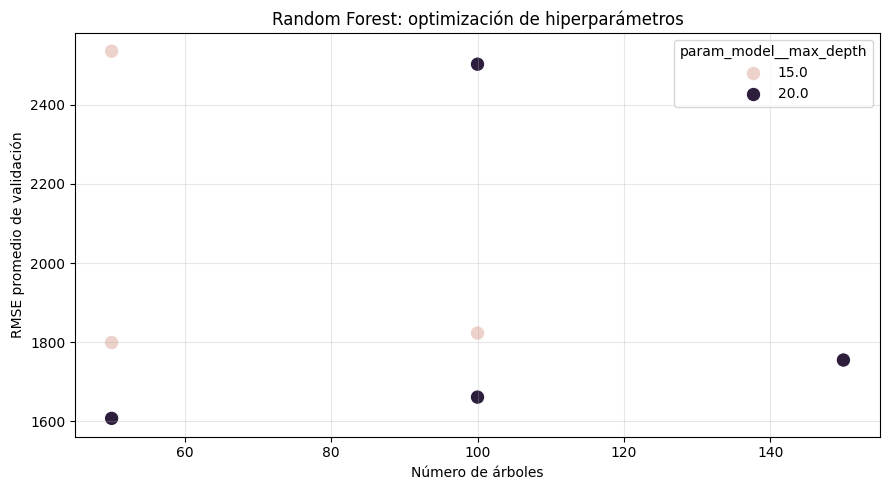

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

grafico_rf = resultados_rf.copy()

grafico_rf["RMSE"] = -grafico_rf["mean_test_score"]

grafico_rf["n_estimators"] = (
    grafico_rf["param_model__n_estimators"].astype(int)
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=grafico_rf,
    x="n_estimators",
    y="RMSE",
    hue="param_model__max_depth",
    s=110
)

plt.title("Random Forest: optimización de hiperparámetros")
plt.xlabel("Número de árboles")
plt.ylabel("RMSE promedio de validación")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de la optimización de Random Forest**

Se realizó una optimización exploratoria de hiperparámetros mediante RandomizedSearchCV, evaluando ocho configuraciones del algoritmo Random Forest con cuatro particiones de validación temporal, para un total de 32 ajustes.

El procedimiento se desarrolló sobre una muestra reproducible de 156.837 observaciones, conservando la estructura cronológica de los datos.

La mejor configuración encontrada utilizó 50 árboles de decisión, una profundidad máxima de 20 niveles, un mínimo de cinco observaciones por hoja y la totalidad de las características transformadas.

Esta configuración alcanzó un RMSE promedio de validación de 1.607,80, frente a un RMSE promedio de entrenamiento de 1.125,40.

La diferencia entre ambos errores sugiere una brecha de generalización que podría estar relacionada con sobreajuste y variaciones temporales en los patrones de ventas.

Asimismo, los resultados evidencian que incrementar el número de árboles no garantiza una mejora del rendimiento, puesto que el comportamiento predictivo depende de la interacción entre los diferentes hiperparámetros.

El proceso de optimización tuvo una duración aproximada de 15,41 minutos.

Estos resultados corresponden a una optimización exploratoria sobre una muestra del conjunto de entrenamiento y deberán contrastarse posteriormente con el desempeño sobre datos cronológicamente posteriores.

### 10.10. OPTIMIZACIÓN DE XGBOOST
Ahora debemos optimizar el segundo algoritmo utilizando exactamente las mismas particiones temporales y métricas, para realizar una comparación justa.
Como Random Forest tardó aproximadamente 15 minutos, comenzaremos con una búsqueda exploratoria de ocho configuraciones de XGBoost.

In [29]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

parametros_xgb = {
    "feature_selection__k": [10, 15, 20, "all"],
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

busqueda_xgb = RandomizedSearchCV(
    estimator=clone(pipeline_xgb),
    param_distributions=parametros_xgb,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=splits_opt,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=False,
    error_score="raise",
    return_train_score=True
)

print("Búsqueda XGBoost configurada")
print("Combinaciones:", busqueda_xgb.n_iter)
print("Particiones:", len(splits_opt))
print("Entrenamientos:", 8 * len(splits_opt))


Búsqueda XGBoost configurada
Combinaciones: 8
Particiones: 4
Entrenamientos: 32


### 10.11 EJECUTAR OPTIMIZACIÓN XGBOOST

In [30]:
import time

inicio_xgb = time.time()

busqueda_xgb.fit(X_opt, y_opt)

tiempo_xgb = (time.time() - inicio_xgb) / 60

print("\nOPTIMIZACIÓN XGBOOST FINALIZADA")
print(f"Tiempo: {tiempo_xgb:.2f} minutos")

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_xgb.best_params_.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor RMSE promedio CV: "
    f"{-busqueda_xgb.best_score_:.2f}"
)


Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV] END feature_selection__k=all, model__colsample_bytree=1.0, model__learning_rate=0.1, model__max_depth=5, model__n_estimators=300, model__subsample=0.8; total time=   1.6s
[CV] END feature_selection__k=all, model__colsample_bytree=1.0, model__learning_rate=0.1, model__max_depth=5, model__n_estimators=300, model__subsample=0.8; total time=   6.0s
[CV] END feature_selection__k=all, model__colsample_bytree=1.0, model__learning_rate=0.1, model__max_depth=5, model__n_estimators=300, model__subsample=0.8; total time=   3.6s
[CV] END feature_selection__k=all, model__colsample_bytree=1.0, model__learning_rate=0.1, model__max_depth=5, model__n_estimators=300, model__subsample=0.8; total time=   7.0s
[CV] END feature_selection__k=10, model__colsample_bytree=1.0, model__learning_rate=0.05, model__max_depth=3, model__n_estimators=200, model__subsample=1.0; total time=   0.6s
[CV] END feature_selection__k=10, model__colsample_bytree=1.

### 10.12 RESULTADOS DE XGBOOST

,rank_test_score,RMSE_validacion,RMSE_entrenamiento,param_feature_selection__k,param_model__n_estimators,param_model__max_depth,param_model__learning_rate
0,1,1589.80,1249.17,all,300,5,0.10
7,2,1923.53,1651.32,15,300,5,0.10
4,3,2003.50,1733.04,all,200,7,0.03
6,4,2425.47,2319.05,all,100,3,0.10
5,5,2487.56,2392.59,20,300,3,0.03
3,6,2586.84,2453.93,10,100,7,0.05
2,7,2595.86,2522.28,15,100,3,0.05
1,8,2647.83,2575.49,10,200,3,0.05


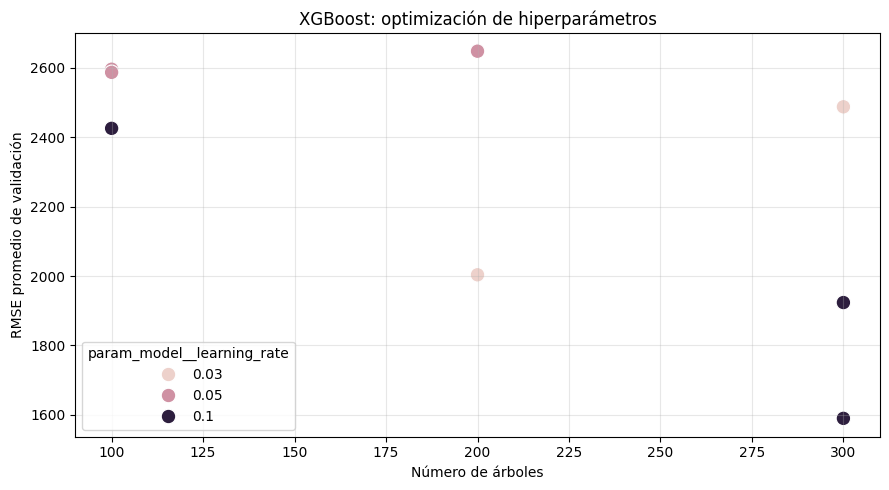

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

resultados_xgb = pd.DataFrame(busqueda_xgb.cv_results_)

resultados_xgb["RMSE_validacion"] = (
    -resultados_xgb["mean_test_score"]
)

resultados_xgb["RMSE_entrenamiento"] = (
    -resultados_xgb["mean_train_score"]
)

columnas = [
    "rank_test_score",
    "RMSE_validacion",
    "RMSE_entrenamiento",
    "param_feature_selection__k",
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__learning_rate"
]

display(
    resultados_xgb[columnas]
    .sort_values("RMSE_validacion")
    .round(2)
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=resultados_xgb,
    x="param_model__n_estimators",
    y="RMSE_validacion",
    hue="param_model__learning_rate",
    s=110
)

plt.title("XGBoost: optimización de hiperparámetros")
plt.xlabel("Número de árboles")
plt.ylabel("RMSE promedio de validación")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de la optimización de XGBoost y comparación preliminar**

Se implementó la optimización del algoritmo XGBoost mediante RandomizedSearchCV, utilizando ocho configuraciones de hiperparámetros y cuatro particiones de validación temporal, para un total de 32 ajustes.

La mejor configuración utilizó 300 árboles, profundidad máxima de cinco niveles, tasa de aprendizaje de 0,1, proporción de muestreo de observaciones de 0,8 y proporción de características por árbol de 1,0. El procedimiento seleccionó la totalidad de las características transformadas.

El modelo obtuvo un RMSE promedio de validación de 1.589,80 y un RMSE promedio de entrenamiento de 1.249,17.

Al comparar los mejores resultados exploratorios, XGBoost presentó un RMSE aproximadamente un 1,12 % inferior al de Random Forest, cuyo error fue de 1.607,80.

Asimismo, XGBoost completó la optimización en 1,64 minutos, frente a los 15,41 minutos requeridos por Random Forest, evidenciando una ventaja computacional en las condiciones experimentales utilizadas.

No obstante, estas diferencias corresponden a resultados obtenidos durante la selección de hiperparámetros y no constituyen evidencia suficiente de superioridad estadística.

Por tanto, se requiere una evaluación comparativa posterior, utilizando predicciones pareadas sobre datos no empleados durante la optimización, para determinar si las diferencias observadas son consistentes.

## 11. Comparación estadística de Random Forest y XGBoost.

### 11.1 ENTRENAMIENTO DE MODELOS OPTIMIZADOS
Este entrenamiento utiliza las 785.727 observaciones de entrenamiento y deja intacto el conjunto de prueba de junio y julio de 2015.

In [32]:
from sklearn.base import clone
import time

# Recuperar las mejores configuraciones
modelo_rf_final = clone(pipeline_rf)
modelo_rf_final.set_params(**busqueda_rf.best_params_)

modelo_xgb_final = clone(pipeline_xgb)
modelo_xgb_final.set_params(**busqueda_xgb.best_params_)

# Limitar paralelización de Random Forest
modelo_rf_final.set_params(model__n_jobs=2)

# Entrenar Random Forest
inicio = time.time()

modelo_rf_final.fit(X_train, y_train)

print(
    "Random Forest entrenado en",
    round((time.time() - inicio) / 60, 2),
    "minutos"
)

# Entrenar XGBoost
inicio = time.time()

modelo_xgb_final.fit(X_train, y_train)

print(
    "XGBoost entrenado en",
    round((time.time() - inicio) / 60, 2),
    "minutos"
)


Random Forest entrenado en 3.71 minutos
XGBoost entrenado en 0.5 minutos


### 11.2 EVALUACIÓN FINAL


In [33]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predicciones
pred_rf = modelo_rf_final.predict(X_test)
pred_xgb = modelo_xgb_final.predict(X_test)

# Función de evaluación
def evaluar_modelo(nombre, reales, predicciones):
    return {
        "Modelo": nombre,
        "RMSE": np.sqrt(
            mean_squared_error(reales, predicciones)
        ),
        "MAE": mean_absolute_error(
            reales, predicciones
        ),
        "R2": r2_score(
            reales, predicciones
        )
    }

comparacion_final = pd.DataFrame([
    evaluar_modelo("Random Forest", y_test, pred_rf),
    evaluar_modelo("XGBoost", y_test, pred_xgb)
])

display(comparacion_final.round(4))


,Modelo,RMSE,MAE,R2
0,Random Forest,1318.2430,903.1914,0.8205
1,XGBoost,1484.9506,1094.2092,0.7722


**Interpretación de la evaluación final de Random Forest y XGBoost**

Los modelos optimizados fueron entrenados utilizando el conjunto completo de entrenamiento, compuesto por 785.727 observaciones, y evaluados sobre un conjunto de prueba cronológicamente posterior de 58.611 registros.

Random Forest obtuvo un RMSE de 1.318,24, un MAE de 903,19 y un coeficiente de determinación R² de 0,8205.

Por su parte, XGBoost alcanzó un RMSE de 1.484,95, un MAE de 1.094,21 y un R² de 0,7722.

Los resultados evidencian que Random Forest presentó un mejor desempeño predictivo en las tres métricas consideradas. En particular, su RMSE fue aproximadamente un 11,23 % inferior al de XGBoost.

Aunque XGBoost había presentado un error ligeramente menor durante la optimización exploratoria, esta ventaja no se mantuvo al evaluar ambos modelos sobre observaciones futuras.

En términos computacionales, XGBoost presentó un menor tiempo de entrenamiento, con aproximadamente 0,50 minutos frente a los 3,71 minutos requeridos por Random Forest.

Estos resultados muestran que la selección de algoritmos debe considerar tanto su desempeño predictivo como su eficiencia computacional y capacidad de generalización temporal.

En el conjunto de prueba analizado, Random Forest presentó el mejor desempeño predictivo, mientras que XGBoost ofreció una mayor velocidad de entrenamiento.

### 11.3. Comparación estadística de los errores
Utilizaremos una prueba de Wilcoxon sobre pérdidas agregadas por semana. Esta prueba será complementaria: los bloques semanales pueden conservar dependencia temporal, por lo que no debemos interpretarla como una demostración definitiva de superioridad estadística.

In [34]:
from scipy.stats import wilcoxon

# Recuperar fechas de prueba
fechas_test = pd.to_datetime(
    df_model.loc[X_test.index, "Date"]
)

errores = pd.DataFrame({
    "Date": fechas_test.to_numpy(),
    "Real": np.asarray(y_test),
    "Pred_RF": pred_rf,
    "Pred_XGB": pred_xgb
})

# Errores cuadráticos
errores["SE_RF"] = (
    errores["Real"] - errores["Pred_RF"]
) ** 2

errores["SE_XGB"] = (
    errores["Real"] - errores["Pred_XGB"]
) ** 2

# Agrupar por semanas
errores["Semana"] = (
    errores["Date"].dt.to_period("W").astype(str)
)

comparacion_semanal = (
    errores.groupby("Semana")[["SE_RF", "SE_XGB"]]
    .mean()
)

comparacion_semanal["RMSE_RF"] = np.sqrt(
    comparacion_semanal["SE_RF"]
)

comparacion_semanal["RMSE_XGB"] = np.sqrt(
    comparacion_semanal["SE_XGB"]
)

display(comparacion_semanal.round(2))


,SE_RF,SE_XGB,RMSE_RF,RMSE_XGB
Semana,,,,
2015-06-01/2015-06-07,2874798.95,3190340.52,1695.52,1786.15
2015-06-08/2015-06-14,897521.01,1248242.51,947.38,1117.25
2015-06-15/2015-06-21,1492882.24,2259809.06,1221.84,1503.27
2015-06-22/2015-06-28,978129.01,1327197.50,989.00,1152.04
2015-06-29/2015-07-05,3982399.12,4563349.60,1995.59,2136.20
2015-07-06/2015-07-12,1224926.08,1426293.58,1106.76,1194.28
2015-07-13/2015-07-19,1449823.83,2122067.04,1204.09,1456.73
2015-07-20/2015-07-26,1062678.32,1336271.42,1030.86,1155.97
2015-07-27/2015-08-02,1800451.08,2524657.45,1341.81,1588.92


### 11.4 PRUEBA ESTADÍSTICA DE WILCOXON

In [35]:
# Diferencias pareadas de pérdidas cuadráticas semanales
diferencias = (
    comparacion_semanal["SE_RF"]
    - comparacion_semanal["SE_XGB"]
)

estadistico, p_valor = wilcoxon(
    diferencias,
    alternative="two-sided",
    zero_method="wilcox"
)

print("PRUEBA DE WILCOXON")
print(f"Estadístico: {estadistico:.4f}")
print(f"P-valor: {p_valor:.6f}")
print(f"Semanas evaluadas: {len(diferencias)}")

print("\nHipótesis:")
print("H0: La diferencia de pérdidas es simétrica alrededor de cero.")
print("H1: La diferencia de pérdidas no es simétrica alrededor de cero.")

if p_valor < 0.05:
    print("\nSe rechaza H0 al 5 %.")
else:
    print("\nNo se rechaza H0 al 5 %.")

print(
    "\nSemanas con menor error de Random Forest:",
    (diferencias < 0).sum()
)

print(
    "Semanas con menor error de XGBoost:",
    (diferencias > 0).sum()
)


PRUEBA DE WILCOXON
Estadístico: 0.0000
P-valor: 0.003906
Semanas evaluadas: 9

Hipótesis:
H0: La diferencia de pérdidas es simétrica alrededor de cero.
H1: La diferencia de pérdidas no es simétrica alrededor de cero.

Se rechaza H0 al 5 %.

Semanas con menor error de Random Forest: 9
Semanas con menor error de XGBoost: 0


### 11.5 COMPARACIÓN SEMANAL

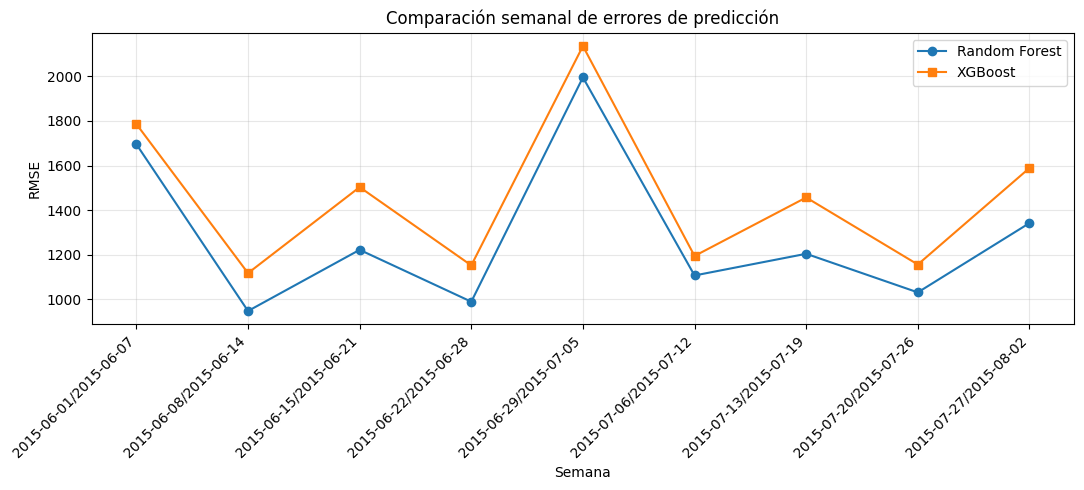

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    comparacion_semanal.index,
    comparacion_semanal["RMSE_RF"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    comparacion_semanal.index,
    comparacion_semanal["RMSE_XGB"],
    marker="s",
    label="XGBoost"
)

plt.title("Comparación semanal de errores de predicción")
plt.xlabel("Semana")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de la comparación estadística**

Se realizó una comparación de los errores de predicción de Random Forest y XGBoost mediante la prueba no paramétrica de rangos con signo de Wilcoxon, utilizando las pérdidas cuadráticas medias agregadas por semana.

El análisis comprendió nueve períodos semanales del conjunto de prueba, correspondientes a junio y julio de 2015.

Random Forest presentó menores errores de predicción en las nueve semanas evaluadas, mostrando un comportamiento favorable y consistente frente a XGBoost.

La prueba de Wilcoxon obtuvo un estadístico W = 0 y un p-valor bilateral de 0,003906.

Bajo los supuestos de la prueba, este resultado permite rechazar la hipótesis nula de simetría de las diferencias de pérdidas alrededor de cero, utilizando un nivel de significancia del 5 %.

Los resultados respaldan la ventaja observada de Random Forest en el conjunto de prueba. No obstante, debido a la posible dependencia entre semanas consecutivas y al número limitado de períodos evaluados, la significancia estadística debe interpretarse con cautela.

En consecuencia, se considera que Random Forest presentó el mejor desempeño predictivo durante el período analizado, sin afirmar que necesariamente será superior en todos los escenarios futuros.

## 12. Curva de aprendizaje de Random Forest
Como Random Forest fue nuestro mejor modelo en el conjunto de prueba, lo utilizaremos para esta visualización.

Hay tres comportamientos que debemos analizar:
- Sobreajuste: el RMSE de entrenamiento es considerablemente menor que el de validación.
- Mejora con más datos: el RMSE de validación disminuye al aumentar las observaciones.
- Estabilización: agregar más datos produce mejoras pequeñas, lo que puede indicar que necesitamos mejorar características o hiperparámetros.

### 12.1 PREPARACIÓN DE CURVA DE APRENDIZAJE

In [37]:
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Utilizar el último fold temporal de la muestra
idx_tr, idx_val = splits_opt[-1]

X_base = X_opt.iloc[idx_tr]
y_base = y_opt.iloc[idx_tr]

X_validacion = X_opt.iloc[idx_val]
y_validacion = y_opt.iloc[idx_val]

# Tamaños progresivos del conjunto de entrenamiento
fracciones = [0.2, 0.4, 0.6, 0.8, 1.0]

resultados_aprendizaje = []

print("Entrenamiento disponible:", len(X_base))
print("Validación:", len(X_validacion))


Entrenamiento disponible: 125834
Validación: 31003


### 12.2 CURVA DE APRENDIZAJE
Esta curva utiliza ventanas de entrenamiento crecientes que terminan en la misma fecha. Así mantenemos fijo el período de validación y evitamos entrenar con información posterior.

In [38]:
for fraccion in fracciones:

    n = int(len(X_base) * fraccion)

    # Utilizar las observaciones cronológicamente
    # más recientes dentro del entrenamiento
    X_sub = X_base.iloc[-n:]
    y_sub = y_base.iloc[-n:]

    modelo = clone(pipeline_rf)

    modelo.set_params(
        **busqueda_rf.best_params_
    )

    modelo.set_params(model__n_jobs=2)

    inicio = time.time()

    modelo.fit(X_sub, y_sub)

    pred_train = modelo.predict(X_sub)
    pred_val = modelo.predict(X_validacion)

    rmse_train = np.sqrt(
        mean_squared_error(y_sub, pred_train)
    )

    rmse_val = np.sqrt(
        mean_squared_error(y_validacion, pred_val)
    )

    resultados_aprendizaje.append({
        "Observaciones": n,
        "RMSE_Entrenamiento": rmse_train,
        "RMSE_Validacion": rmse_val,
        "Tiempo_segundos": time.time() - inicio
    })

    print(
        f"{n:,} registros | "
        f"RMSE Train: {rmse_train:.2f} | "
        f"RMSE Val: {rmse_val:.2f}"
    )

df_aprendizaje = pd.DataFrame(resultados_aprendizaje)

display(df_aprendizaje.round(2))


25,166 registros | RMSE Train: 1153.36 | RMSE Val: 1991.35
50,333 registros | RMSE Train: 1043.94 | RMSE Val: 1700.31
75,500 registros | RMSE Train: 1186.05 | RMSE Val: 1727.99
100,667 registros | RMSE Train: 1122.87 | RMSE Val: 1677.17
125,834 registros | RMSE Train: 1089.12 | RMSE Val: 1610.50


,Observaciones,RMSE_Entrenamiento,RMSE_Validacion,Tiempo_segundos
0,25166,1153.36,1991.35,9.72
1,50333,1043.94,1700.31,23.10
2,75500,1186.05,1727.99,23.08
3,100667,1122.87,1677.17,42.47
4,125834,1089.12,1610.50,42.80


### 12.3 VISUALIZACIÓN CURVA DE APRENDIZAJE

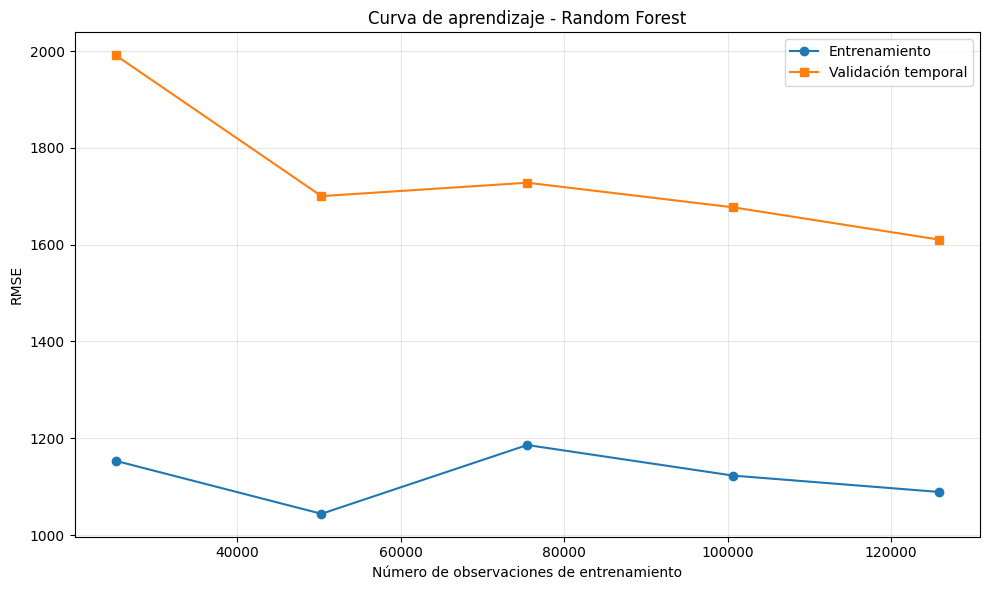

In [39]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_aprendizaje["Observaciones"],
    df_aprendizaje["RMSE_Entrenamiento"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    df_aprendizaje["Observaciones"],
    df_aprendizaje["RMSE_Validacion"],
    marker="s",
    label="Validación temporal"
)

plt.title("Curva de aprendizaje - Random Forest")
plt.xlabel("Número de observaciones de entrenamiento")
plt.ylabel("RMSE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de la curva de aprendizaje de Random Forest**

Se construyó una curva de aprendizaje para analizar el comportamiento predictivo de Random Forest al incrementar progresivamente el número de observaciones utilizadas durante el entrenamiento.

El experimento consideró cinco tamaños de entrenamiento, desde 25.166 hasta 125.834 registros, manteniendo un conjunto de validación temporal fijo de 31.003 observaciones.

Los resultados muestran una reducción del RMSE de validación desde 1.991,35 hasta 1.610,50, equivalente a una mejora aproximada del 19,1 %.

Esta tendencia evidencia que la incorporación de información histórica adicional favoreció, en términos generales, la capacidad predictiva del modelo.

No obstante, se observaron fluctuaciones intermedias en el error, lo que sugiere que el desempeño también depende de las características de los períodos incorporados.

Por otra parte, el RMSE de entrenamiento permaneció por debajo del RMSE de validación en todas las configuraciones, indicando una brecha de generalización compatible con sobreajuste y posibles variaciones temporales en los patrones de ventas.

En conclusión, Random Forest mostró una mejora general en su desempeño predictivo al ampliar el conjunto histórico de entrenamiento, aunque persiste una diferencia entre los errores de entrenamiento y validación que podría abordarse mediante ingeniería de características y ajustes adicionales del modelo.

## 13. Visualización del espacio de características con t-SNE

### 13.1 PREPARACIÓN PARA T-SNE

In [40]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Muestra reproducible del entrenamiento
rng = np.random.default_rng(42)

n_muestra = min(2000, len(X_train))

indices_tsne = rng.choice(
    len(X_train),
    size=n_muestra,
    replace=False
)

X_tsne = X_train.iloc[indices_tsne].copy()
y_tsne = y_train.iloc[indices_tsne].copy()

# Ajustar el preprocesador solo con datos de entrenamiento
preprocessor_tsne = clone(preprocessor)

X_transformado = preprocessor_tsne.fit_transform(X_tsne)

# Convertir a matriz densa si es necesario
if hasattr(X_transformado, "toarray"):
    X_transformado = X_transformado.toarray()

# Estandarizar características
escalador_tsne = StandardScaler()

X_escalado = escalador_tsne.fit_transform(
    X_transformado
)

print("Muestra:", X_escalado.shape)
print("Variable objetivo:", y_tsne.shape)


Muestra: (2000, 25)
Variable objetivo: (2000,)


### 13.2 REDUCCIÓN DE DIMENSIONALIDAD CON T-SNE

In [41]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne_2d = tsne.fit_transform(X_escalado)

df_tsne = pd.DataFrame({
    "TSNE_1": X_tsne_2d[:, 0],
    "TSNE_2": X_tsne_2d[:, 1],
    "Sales": y_tsne.to_numpy()
})

print("Dimensiones finales:", df_tsne.shape)

display(df_tsne.head())


Dimensiones finales: (2000, 3)


,TSNE_1,TSNE_2,Sales
0,-27.279665,18.252756,6679
1,60.364647,-4.743292,5201
2,28.491625,18.784655,7844
3,23.129189,-53.583530,4007
4,-21.810776,-36.032429,3289


### 13.3 VISUALIZACIÓN T-SNE

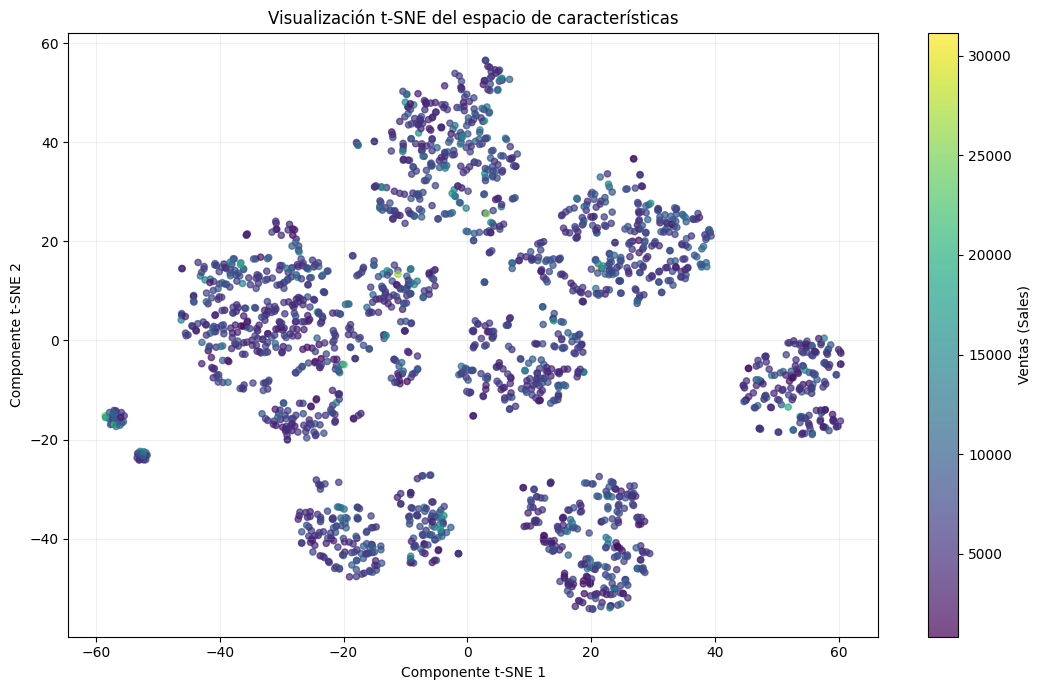

In [42]:
plt.figure(figsize=(11, 7))

grafico = plt.scatter(
    df_tsne["TSNE_1"],
    df_tsne["TSNE_2"],
    c=df_tsne["Sales"],
    cmap="viridis",
    s=20,
    alpha=0.7
)

plt.colorbar(
    grafico,
    label="Ventas (Sales)"
)

plt.title(
    "Visualización t-SNE del espacio de características"
)

plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Interpretación de la visualización t-SNE

Se aplicó la técnica de reducción de dimensionalidad t-Distributed Stochastic Neighbor Embedding (t-SNE) para representar en dos dimensiones el espacio de características del conjunto de datos Rossmann Store Sales.

Para el análisis se seleccionó una muestra reproducible de 2.000 observaciones del conjunto de entrenamiento. Después del preprocesamiento, las variables predictoras se representaron mediante 25 características transformadas y estandarizadas.

La visualización permitió identificar diversos agrupamientos de observaciones con características similares, lo que evidencia la existencia de estructuras locales dentro del espacio de características.

Al utilizar la variable `Sales` como escala de color, se observó que los diferentes niveles de ventas se encuentran distribuidos entre varios agrupamientos, sin una separación claramente definida entre observaciones de ventas altas y bajas.

Este comportamiento sugiere que la relación entre las características predictoras y el volumen de ventas puede ser compleja y depender de interacciones entre múltiples variables.

Los resultados son compatibles con la utilización de algoritmos capaces de representar relaciones no lineales, como Random Forest y XGBoost, aunque la visualización por sí sola no demuestra que estos modelos sean superiores.

Es importante señalar que t-SNE constituye una herramienta exploratoria y no supervisada. Por tanto, los agrupamientos observados no representan necesariamente segmentos comerciales definidos ni permiten establecer relaciones causales.

En conjunto, esta visualización complementa el análisis exploratorio y permite comprender mejor la estructura local del espacio de características utilizado para la predicción de ventas.

## 14. Comparación mediante Repeated K-Fold

### 14.1 REPEATED K-FOLD

In [45]:
from sklearn.model_selection import RepeatedKFold
from sklearn.base import clone
import numpy as np
import pandas as pd
import time

# Configuración de validación cruzada repetida
N_FOLDS = 5
N_REPETICIONES = 2

rkf = RepeatedKFold(
    n_splits=N_FOLDS,
    n_repeats=N_REPETICIONES,
    random_state=42
)

# Recuperar las mejores configuraciones
modelo_rf_rkf = clone(pipeline_rf)

modelo_rf_rkf.set_params(
    **busqueda_rf.best_params_,
    model__n_jobs=2
)

modelo_xgb_rkf = clone(pipeline_xgb)

modelo_xgb_rkf.set_params(
    **busqueda_xgb.best_params_,
    model__n_jobs=2
)

print("REPEATED K-FOLD CONFIGURADO")
print("Folds:", N_FOLDS)
print("Repeticiones:", N_REPETICIONES)
print("Evaluaciones por modelo:", rkf.get_n_splits())
print("Total de entrenamientos:", rkf.get_n_splits() * 2)


REPEATED K-FOLD CONFIGURADO
Folds: 5
Repeticiones: 2
Evaluaciones por modelo: 10
Total de entrenamientos: 20


### 14.2 COMPARACIÓN REPEATED K-FOLD

In [46]:
from sklearn.metrics import mean_squared_error

resultados_rkf = []

inicio_rkf = time.time()

for i, (idx_ent, idx_val) in enumerate(
    rkf.split(X_opt), start=1
):
    X_ent = X_opt.iloc[idx_ent]
    X_val = X_opt.iloc[idx_val]

    y_ent = y_opt.iloc[idx_ent]
    y_val = y_opt.iloc[idx_val]

    rf = clone(modelo_rf_rkf)
    xgb = clone(modelo_xgb_rkf)

    rf.fit(X_ent, y_ent)
    xgb.fit(X_ent, y_ent)

    pred_rf_cv = rf.predict(X_val)
    pred_xgb_cv = xgb.predict(X_val)

    rmse_rf = np.sqrt(
        mean_squared_error(y_val, pred_rf_cv)
    )

    rmse_xgb = np.sqrt(
        mean_squared_error(y_val, pred_xgb_cv)
    )

    resultados_rkf.append({
        "Fold": i,
        "Repeticion": (i - 1) // 5 + 1,
        "RMSE_RF": rmse_rf,
        "RMSE_XGB": rmse_xgb,
        "Diferencia": rmse_rf - rmse_xgb
    })

    print(
        f"Fold {i}/10 | "
        f"RF: {rmse_rf:.2f} | "
        f"XGB: {rmse_xgb:.2f}"
    )

df_rkf = pd.DataFrame(resultados_rkf)

print(
    "\nTiempo total:",
    round((time.time() - inicio_rkf) / 60, 2),
    "minutos"
)

display(df_rkf.round(2))

# =====================================================
# DOCUMENTACIÓN DEL USO DE IA GENERATIVA
# =====================================================
# Herramienta: ChatGPT (OpenAI)
# Propósito: Apoyo en la implementación de Machine Learning.
#
# Descripción de la solicitud:
#
# =====================================================


Fold 1/10 | RF: 1379.17 | XGB: 1354.47
Fold 2/10 | RF: 1385.70 | XGB: 1384.44
Fold 3/10 | RF: 1344.96 | XGB: 1335.99
Fold 4/10 | RF: 1359.76 | XGB: 1335.73
Fold 5/10 | RF: 1393.62 | XGB: 1364.05
Fold 6/10 | RF: 1351.03 | XGB: 1368.45
Fold 7/10 | RF: 1373.88 | XGB: 1366.17
Fold 8/10 | RF: 1357.32 | XGB: 1350.31
Fold 9/10 | RF: 1391.64 | XGB: 1397.81
Fold 10/10 | RF: 1367.39 | XGB: 1346.28

Tiempo total: 7.09 minutos


,Fold,Repeticion,RMSE_RF,RMSE_XGB,Diferencia
0,1,1,1379.17,1354.47,24.70
1,2,1,1385.70,1384.44,1.26
2,3,1,1344.96,1335.99,8.97
3,4,1,1359.76,1335.73,24.03
4,5,1,1393.62,1364.05,29.56
5,6,2,1351.03,1368.45,-17.42
6,7,2,1373.88,1366.17,7.71
7,8,2,1357.32,1350.31,7.01
8,9,2,1391.64,1397.81,-6.17
9,10,2,1367.39,1346.28,21.11


### 14.3 RESUMEN REPEATED K-FOLD

In [47]:
resumen_rkf = pd.DataFrame({
    "Modelo": ["Random Forest", "XGBoost"],
    "RMSE_promedio": [
        df_rkf["RMSE_RF"].mean(),
        df_rkf["RMSE_XGB"].mean()
    ],
    "Desviacion_estandar": [
        df_rkf["RMSE_RF"].std(),
        df_rkf["RMSE_XGB"].std()
    ]
})

display(resumen_rkf.round(2))

print(
    "Folds favorables a Random Forest:",
    (df_rkf["Diferencia"] < 0).sum()
)

print(
    "Folds favorables a XGBoost:",
    (df_rkf["Diferencia"] > 0).sum()
)

# =====================================================
# DOCUMENTACIÓN DEL USO DE IA GENERATIVA
# =====================================================
# Herramienta: ChatGPT (OpenAI)
# Propósito: Apoyo en la implementación de Machine Learning.
#
# Descripción de la solicitud:
#
# =====================================================


,Modelo,RMSE_promedio,Desviacion_estandar
0,Random Forest,1370.45,17.09
1,XGBoost,1360.37,20.08


Folds favorables a Random Forest: 2
Folds favorables a XGBoost: 8



## 14.6. Interpretación de los resultados de Repeated K-Fold

Se realizó una evaluación comparativa de los algoritmos **Random Forest** y **XGBoost** mediante la técnica de validación cruzada repetida (*Repeated K-Fold*), utilizando 5 particiones y 2 repeticiones, para un total de 10 evaluaciones por algoritmo.

El objetivo de este procedimiento fue analizar el desempeño predictivo y la variabilidad de ambos modelos bajo diferentes particiones de los datos.

### 14.6.1. Resultados generales

| Indicador | Random Forest | XGBoost |
|:---|---:|---:|
| **RMSE promedio** | 1.370,45 | **1.360,37** |
| Desviación estándar | **17,09** | 20,08 |
| Folds con menor RMSE | 2 | **8** |
| Evaluaciones realizadas | 10 | 10 |

**Resultado principal:** XGBoost obtuvo un RMSE promedio aproximadamente **0,74 % menor** que Random Forest durante la validación cruzada repetida.

### 14.6.2. Interpretación de los resultados

Los resultados muestran que **XGBoost obtuvo menores errores de predicción en 8 de los 10 folds evaluados**, mientras que Random Forest presentó mejores resultados en los 2 folds restantes.

El RMSE promedio de XGBoost fue de 1.360,37, frente a 1.370,45 de Random Forest. Esto representa una diferencia absoluta de aproximadamente 10,08 unidades de ventas y una mejora relativa del 0,74 % respecto al RMSE promedio de Random Forest.

Por otra parte, Random Forest presentó una desviación estándar de 17,09, inferior a los 20,08 obtenidos por XGBoost. Esto indica que los errores de Random Forest mostraron una variabilidad ligeramente menor entre las particiones evaluadas.

En términos generales, ambos algoritmos presentaron resultados relativamente próximos, aunque XGBoost obtuvo una pequeña ventaja en el error promedio.

Es importante señalar que Repeated K-Fold genera particiones aleatorias que no preservan el orden cronológico de las observaciones. Por tanto, estos resultados no necesariamente representan la capacidad de los algoritmos para predecir ventas en períodos futuros.

Además, dado que los hiperparámetros fueron seleccionados previamente utilizando la muestra de optimización, este experimento constituye una evaluación complementaria y no una estimación completamente independiente del rendimiento.

---

## 14.7. Comparación con la evaluación temporal

Previamente, se realizó una evaluación cronológica utilizando un conjunto de prueba correspondiente a fechas posteriores a las observaciones de entrenamiento.

Los resultados obtenidos se comparan con los de Repeated K-Fold.

### 14.7.1. Comparación de resultados

| Evaluación | Random Forest | XGBoost | Mejor resultado |
|:---|---:|---:|:---|
| **Prueba cronológica (RMSE)** | **1.318,24** | 1.484,95 | **Random Forest** |
| **Repeated K-Fold (RMSE medio)** | 1.370,45 | **1.360,37** | **XGBoost** |

### 14.7.2. Interpretación metodológica

Los resultados evidencian diferencias en el desempeño relativo de los algoritmos dependiendo de la estrategia de evaluación utilizada.

**Validación temporal:**

Esta metodología respeta el orden cronológico de las observaciones, utilizando información histórica para predecir períodos posteriores.

En esta evaluación, Random Forest obtuvo un RMSE de 1.318,24, mientras que XGBoost registró 1.484,95.

Por tanto, Random Forest presentó un mejor desempeño predictivo sobre el conjunto de prueba temporal.

**Repeated K-Fold:**

Esta metodología permite evaluar los modelos mediante múltiples particiones aleatorias de los datos, proporcionando información sobre la variabilidad de sus resultados.

En este experimento, XGBoost obtuvo un RMSE promedio ligeramente inferior al de Random Forest.

Sin embargo, debido a que las particiones no preservan la secuencia temporal, esta metodología no reproduce completamente las condiciones de un escenario real de pronóstico de ventas futuras.

### 14.7.3. Selección preliminar del mejor modelo

Considerando que el objetivo del proyecto consiste en predecir las ventas futuras de los establecimientos Rossmann, la evaluación cronológica tiene mayor relevancia desde una perspectiva operativa.

En consecuencia, **Random Forest se mantiene como el modelo candidato principal para el pronóstico de ventas**, debido a su mejor desempeño sobre el conjunto de prueba temporal.

No obstante, XGBoost demostró un comportamiento competitivo durante la validación cruzada repetida, por lo que constituye una alternativa relevante.

Esta selección se considera preliminar y está condicionada a los resultados obtenidos durante los períodos evaluados.

### 14.7.4. Conclusión de la comparación

La comparación permitió identificar que el desempeño relativo de los algoritmos depende de la estrategia de validación empleada.

Mientras XGBoost presentó una ligera ventaja en Repeated K-Fold, Random Forest obtuvo mejores resultados en la evaluación cronológica.

Estos hallazgos destacan la importancia de seleccionar metodologías de validación coherentes con la naturaleza temporal del problema.

Para aplicaciones relacionadas con planificación de demanda y pronóstico de ventas, resulta fundamental evaluar los modelos sobre períodos posteriores a los utilizados durante el entrenamiento, evitando incorporar información futura.

Finalmente, la diferencia observada en Repeated K-Fold deberá complementarse con una prueba estadística apropiada para determinar si existe evidencia suficiente de una diferencia sistemática entre ambos algoritmos.


### 14.8 Prueba estadística corregida
Hipótesis estadísticas
- \(H_0\): la diferencia media de RMSE entre Random Forest y XGBoost es igual a cero.
- \(H_1\): la diferencia media de RMSE entre ambos algoritmos es distinta de cero.
Utilizaremos un nivel de significancia del 5 %.
Este test es una aproximación para corregir la dependencia entre particiones, no una garantía de independencia ni una prueba de rendimiento futuro.

In [50]:
# PRUEBA T CORREGIDA PARA REPEATED K-FOLD
from scipy.stats import t
import numpy as np

# Diferencia positiva: XGBoost tiene menor RMSE
diferencias = (
    df_rkf["RMSE_RF"] - df_rkf["RMSE_XGB"]
).to_numpy()

n = len(diferencias)
media_diferencias = np.mean(diferencias)
desv_diferencias = np.std(diferencias, ddof=1)

# Proporción validación / entrenamiento
# Repeated K-Fold con 5 folds: 20% / 80%
ratio = 1 / (N_FOLDS - 1)

# Corrección aproximada de Nadeau y Bengio
error_estandar_corregido = (
    desv_diferencias * np.sqrt(1/n + ratio)
)

t_estadistico = (
    media_diferencias / error_estandar_corregido
)

grados_libertad = n - 1

p_valor = 2 * t.sf(
    abs(t_estadistico),
    df=grados_libertad
)

alpha = 0.05

t_critico = t.ppf(
    1 - alpha/2,
    df=grados_libertad
)

ic_inferior = (
    media_diferencias
    - t_critico * error_estandar_corregido
)

ic_superior = (
    media_diferencias
    + t_critico * error_estandar_corregido
)

print("PRUEBA T CORREGIDA")
print("-" * 45)

print(f"Diferencia media RMSE: {media_diferencias:.2f}")
print(f"Estadístico t: {t_estadistico:.4f}")
print(f"P-valor: {p_valor:.6f}")
print(f"IC 95%: [{ic_inferior:.2f}, {ic_superior:.2f}]")

if p_valor < alpha:
    print("\nSe rechaza H0 al 5%.")
else:
    print("\nNo se rechaza H0 al 5%.")

# =====================================================
# DOCUMENTACIÓN DEL USO DE IA GENERATIVA
# =====================================================
# Herramienta: ChatGPT (OpenAI)
# Propósito: Apoyo en la implementación de Machine Learning.
#
# Descripción de la solicitud:
#
# =====================================================



PRUEBA T CORREGIDA
---------------------------------------------
Diferencia media RMSE: 10.08
Estadístico t: 1.1357
P-valor: 0.285430
IC 95%: [-9.99, 30.14]

No se rechaza H0 al 5%.


### 14.8.1 COMPARACIÓN GRÁFICA REPEATED K-FOLD

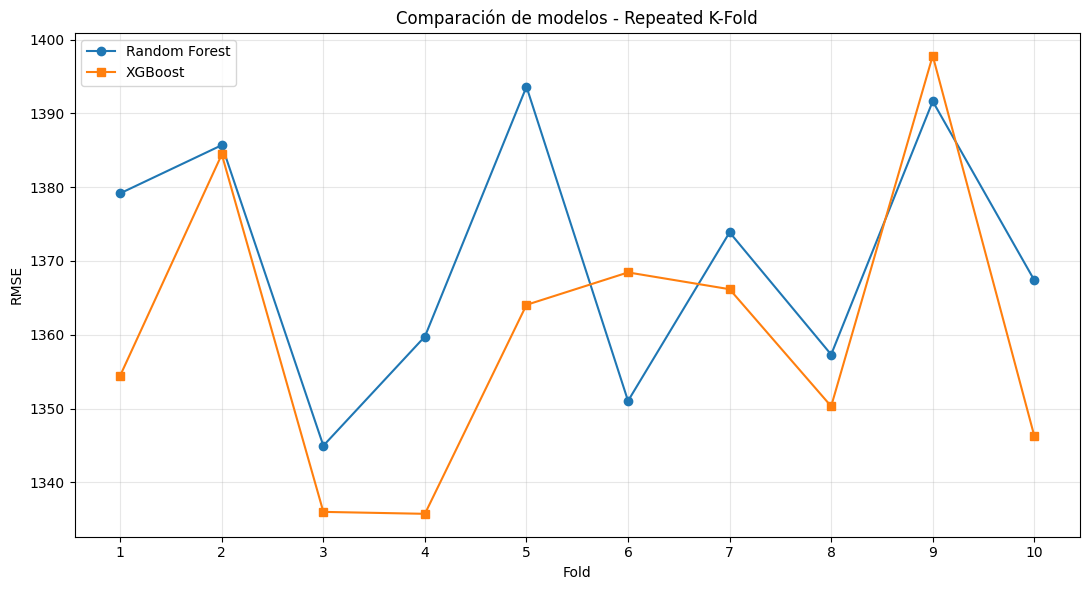

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    df_rkf["Fold"],
    df_rkf["RMSE_RF"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    df_rkf["Fold"],
    df_rkf["RMSE_XGB"],
    marker="s",
    label="XGBoost"
)

plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.title(
    "Comparación de modelos - Repeated K-Fold"
)

plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================
# DOCUMENTACIÓN DEL USO DE IA GENERATIVA
# =====================================================
# Herramienta: ChatGPT (OpenAI)
# Propósito: Apoyo en la implementación de Machine Learning.
#
# Descripción de la solicitud:
#
# =====================================================



## 14.8. Interpretación de la prueba estadística corregida

Se aplicó una prueba t corregida para validación cruzada repetida, con el objetivo de comparar los errores de predicción de Random Forest y XGBoost, considerando parcialmente la dependencia existente entre las particiones de entrenamiento y validación.

### 14.8.1. Resultados del contraste estadístico

| Indicador | Resultado |
|:---|---:|
| Diferencia media de RMSE (RF - XGB) | 10,08 |
| Estadístico t | 1,1357 |
| P-valor bilateral | 0,285430 |
| Límite inferior del IC 95 % | -9,99 |
| Límite superior del IC 95 % | 30,14 |
| Nivel de significancia | 0,05 |
| Decisión | No rechazar H₀ |

### 14.8.2. Hipótesis estadísticas

**Hipótesis nula (H₀):** la diferencia media de los errores RMSE entre Random Forest y XGBoost es igual a cero.

**Hipótesis alternativa (H₁):** la diferencia media de los errores RMSE entre ambos algoritmos es distinta de cero.

### 14.8.3. Interpretación

Los resultados muestran una diferencia media de RMSE de 10,08 unidades a favor de XGBoost.

Sin embargo, la prueba t corregida obtuvo un p-valor de 0,285430, superior al nivel de significancia establecido de 0,05.

Por tanto, **no se rechaza la hipótesis nula**, debido a que no existe evidencia estadística suficiente para concluir que los algoritmos presentan diferencias sistemáticas en sus errores de predicción bajo el procedimiento de evaluación aplicado.

Adicionalmente, el intervalo de confianza del 95 %, comprendido entre -9,99 y 30,14, incluye el valor cero, lo que es consistente con la decisión estadística.

Aunque XGBoost obtuvo menores errores en 8 de las 10 particiones, esta ventaja no resultó estadísticamente significativa bajo el contraste corregido.

Es importante destacar que la ausencia de significancia estadística no demuestra que ambos modelos sean equivalentes.

### 14.8.4. Interpretación de la gráfica

La comparación gráfica de los errores RMSE obtenidos durante Repeated K-Fold evidencia que ambos modelos presentan comportamientos relativamente similares.

XGBoost registró menores errores en la mayoría de las particiones, mientras que Random Forest obtuvo mejores resultados en dos de ellas.

La magnitud de las diferencias varió entre los folds, sin mostrar una ventaja suficientemente concluyente bajo el contraste estadístico aplicado.

### 14.8.5. Conclusión de la comparación estadística

La evaluación mediante Repeated K-Fold permitió comparar el desempeño predictivo de Random Forest y XGBoost bajo múltiples particiones de los datos.

Aunque XGBoost obtuvo un RMSE promedio ligeramente inferior, la prueba estadística corregida no encontró evidencia suficiente para establecer una diferencia significativa entre ambos algoritmos al nivel del 5 %.

Considerando que el objetivo principal del proyecto es pronosticar ventas futuras, se prioriza el desempeño obtenido mediante validación cronológica.

En este contexto, **Random Forest se mantiene como el modelo candidato principal**, dado que obtuvo un menor error de predicción sobre el conjunto de prueba temporal.

No obstante, los resultados estadísticos deben interpretarse con cautela debido a la dependencia entre particiones, la selección previa de hiperparámetros y la naturaleza temporal del conjunto de datos.



# 15. CONCLUSIONES GENERALES DEL PROYECTO

## 15.1. Cumplimiento del objetivo

El presente proyecto tuvo como objetivo desarrollar y evaluar modelos de Machine Learning para la predicción de ventas de los establecimientos de la cadena Rossmann, utilizando información histórica y características operativas, comerciales y temporales.

Para ello, se implementó una metodología que comprendió el análisis exploratorio de datos (EDA), la preparación e ingeniería de características, la selección de variables, la construcción de pipelines, la optimización de hiperparámetros y la comparación de dos algoritmos de aprendizaje supervisado: **Random Forest y XGBoost**.

Los resultados obtenidos permitieron identificar patrones relevantes en el comportamiento de las ventas y evaluar la capacidad predictiva de ambos algoritmos, considerando diferentes estrategias de validación.

## 15.2. Principales hallazgos del análisis exploratorio

El análisis exploratorio permitió estudiar **1.017.209 observaciones correspondientes a 1.115 establecimientos comerciales**, durante el período comprendido entre enero de 2013 y julio de 2015.

Entre los principales hallazgos se identificaron:

- La distribución de las ventas presentó asimetría positiva, con una mayor concentración de observaciones en niveles moderados y una menor proporción de ventas elevadas.
- Se observaron diferencias en las ventas promedio según el día de la semana, el mes y el tipo de establecimiento.
- Las tiendas con promociones activas registraron mayores ventas promedio que aquellas sin promociones, aunque esta asociación no implica necesariamente causalidad.
- Se identificaron valores faltantes en variables relacionadas con promociones secundarias y características de la competencia, lo que justificó la implementación de estrategias de imputación dentro de los pipelines.
- La integración de las tablas de ventas y características de establecimientos se realizó sin pérdidas de registros ni duplicados por combinación de tienda y fecha.

Estos hallazgos evidenciaron la importancia de incorporar variables temporales, operativas y comerciales para representar el comportamiento de las ventas.

## 15.3. Preparación de datos e ingeniería de características

La preparación de los datos permitió construir un conjunto de características predictoras a partir de información disponible antes del momento de la predicción.

Se incorporaron variables derivadas de las fechas, como año, mes, semana del año y día del mes, además de las características originales de los establecimientos.

Asimismo, se implementaron pipelines de Scikit-learn para realizar la imputación de valores faltantes, la codificación de variables categóricas y la selección de características mediante el método filter `SelectKBest`, utilizando la función estadística `f_regression`.

La integración de estas transformaciones dentro de los pipelines permitió mantener un procedimiento reproducible y reducir el riesgo de fuga de información durante el ajuste de los modelos.

## 15.4. Optimización de hiperparámetros

Se realizó la optimización de los algoritmos Random Forest y XGBoost mediante búsquedas de hiperparámetros y particiones de validación temporal.

Los mejores resultados de validación obtenidos fueron:

| Modelo | Mejor RMSE de validación |
|:---|---:|
| Random Forest | 1.607,80 |
| **XGBoost** | **1.589,80** |

Durante la optimización, XGBoost obtuvo un RMSE ligeramente inferior al de Random Forest.

Sin embargo, esta ventaja no se mantuvo en la evaluación final sobre el conjunto de prueba cronológico, lo que evidencia que los resultados de validación no garantizan necesariamente el mismo desempeño en períodos posteriores.

La optimización permitió identificar configuraciones competitivas para ambos modelos y demostrar la importancia de evaluar distintas combinaciones de hiperparámetros.

## 15.5. Evaluación predictiva sobre el conjunto de prueba

La evaluación final se realizó sobre un conjunto de prueba cronológico, utilizando observaciones posteriores a las empleadas durante el entrenamiento.

Los resultados fueron:

| Métrica | Random Forest | XGBoost |
|:---|---:|---:|
| **RMSE** | **1.318,24** | 1.484,95 |
| **MAE** | **903,19** | 1.094,21 |
| **R²** | **0,8205** | 0,7722 |

Random Forest obtuvo el mejor desempeño en las tres métricas evaluadas.

Su RMSE fue aproximadamente un **11,23 % menor** que el de XGBoost, mientras que su MAE fue aproximadamente un **17,46 % inferior**.

Adicionalmente, Random Forest alcanzó un coeficiente de determinación R² de 0,8205, lo que indica que explicó aproximadamente el 82,05 % de la variabilidad de las ventas en el conjunto de prueba evaluado.

Estos resultados respaldan la selección de Random Forest como el modelo con mejor desempeño predictivo para el período temporal analizado.

## 15.6. Comparación estadística de los algoritmos

Se realizó una comparación estadística complementaria utilizando Repeated K-Fold con 5 particiones y 2 repeticiones, obteniendo 10 evaluaciones por algoritmo.

Los resultados fueron:

| Indicador | Random Forest | XGBoost |
|:---|---:|---:|
| RMSE promedio | 1.370,45 | **1.360,37** |
| Desviación estándar | **17,09** | 20,08 |
| Folds con menor RMSE | 2 | **8** |

Aunque XGBoost obtuvo un RMSE promedio aproximadamente un 0,74 % menor, la prueba t corregida produjo un p-valor de 0,285430.

Dado que este valor es superior al nivel de significancia de 0,05, no se rechazó la hipótesis nula de igualdad de errores medios bajo los supuestos del contraste aplicado.

Por tanto, no se encontró evidencia estadística suficiente para concluir que ambos algoritmos presentan diferencias sistemáticas en su desempeño bajo esta estrategia de validación.

Este resultado no demuestra que los modelos sean equivalentes, sino que la diferencia observada no fue estadísticamente concluyente.

Es importante considerar que Repeated K-Fold no preserva el orden cronológico, por lo que sus resultados constituyen evidencia complementaria y no sustituyen la evaluación temporal.

## 15.7. Curva de aprendizaje

La curva de aprendizaje de Random Forest permitió analizar el efecto de incorporar progresivamente más observaciones históricas durante el entrenamiento.

Se evaluaron cinco tamaños de entrenamiento, desde 25.166 hasta 125.834 observaciones, manteniendo un conjunto de validación temporal fijo.

El RMSE de validación disminuyó de 1.991,35 a 1.610,50, representando una reducción aproximada del 19,13 %.

Estos resultados sugieren que la incorporación de información histórica adicional favoreció, en términos generales, el desempeño predictivo del modelo.

Sin embargo, se identificó una diferencia persistente entre los errores de entrenamiento y validación, compatible con cierto sobreajuste y posibles cambios temporales en los patrones de ventas.

## 15.8. Visualización del espacio de características con t-SNE

Se utilizó la técnica t-SNE para representar en dos dimensiones una muestra de 2.000 observaciones, a partir de 25 características obtenidas después del preprocesamiento.

La visualización permitió identificar diversos agrupamientos de observaciones con características similares.

No obstante, los diferentes niveles de ventas aparecieron distribuidos entre múltiples agrupamientos, sin una separación claramente definida entre ventas altas y bajas.

Estos resultados evidenciaron la existencia de estructuras locales en el espacio de características, aunque no permiten establecer directamente relaciones causales ni demostrar la superioridad de un algoritmo predictivo.

## 15.9. Aplicaciones comerciales

Desde una perspectiva de gestión empresarial, los resultados del proyecto muestran el potencial del Machine Learning como herramienta de apoyo para la planificación comercial.

Un modelo predictivo de ventas podría contribuir a:

1. **Planificación de demanda:** estimar ventas futuras por establecimiento y período, facilitando la programación de inventarios.
2. **Gestión de abastecimiento:** anticipar necesidades de reposición y reducir riesgos de quiebres de stock o sobreinventario.
3. **Evaluación de promociones:** incorporar información promocional para estimar la demanda esperada bajo diferentes condiciones comerciales.
4. **Negociación con proveedores:** utilizar proyecciones de demanda como insumo para planificar volúmenes de compra y negociar condiciones comerciales.
5. **Planificación operativa:** apoyar decisiones relacionadas con recursos, personal y capacidad de atención.

Estas aplicaciones representan oportunidades potenciales y requieren validaciones adicionales antes de su implementación en un entorno empresarial real.

## 15.10. Limitaciones y trabajos futuros

Entre las principales limitaciones del proyecto se identificaron:

- La información corresponde al período 2013-2015, por lo que los resultados no necesariamente representan condiciones comerciales actuales.
- El conjunto de datos corresponde a una cadena específica de establecimientos, lo que limita la generalización directa a otros sectores comerciales.
- La evaluación mediante Repeated K-Fold no preserva la estructura temporal de los datos.
- Los hiperparámetros utilizados en la comparación repetida fueron seleccionados previamente, por lo que dicha comparación no constituye una evaluación completamente independiente.
- La predicción se desarrolló utilizando las variables disponibles en el dataset, sin incorporar información externa como condiciones meteorológicas, indicadores económicos o eventos extraordinarios.

Como posibles mejoras futuras, se propone:

1. Incorporar variables históricas de ventas, como rezagos y promedios móviles, calculadas exclusivamente con información disponible antes de cada predicción.
2. Evaluar estrategias adicionales de validación temporal mediante múltiples ventanas de entrenamiento y prueba.
3. Investigar nuevas configuraciones de hiperparámetros y técnicas de ingeniería de características.
4. Incorporar información externa relevante para el comportamiento de la demanda.
5. Evaluar el desempeño de los modelos por tienda, tipo de establecimiento y período comercial.
6. Desarrollar un prototipo que permita utilizar las predicciones en procesos de planificación de demanda.

## 15.11. Conclusión final

El proyecto permitió aplicar una metodología integral de Machine Learning para abordar un problema realista de predicción de ventas comerciales.

Los resultados demostraron que Random Forest y XGBoost constituyen alternativas competitivas para modelar el comportamiento de las ventas a partir de características temporales, operativas y comerciales.

Aunque XGBoost obtuvo una ligera ventaja durante la validación cruzada repetida, la comparación estadística corregida no identificó evidencia suficiente de una diferencia significativa entre ambos algoritmos bajo ese procedimiento.

Por otra parte, **Random Forest presentó el mejor desempeño sobre el conjunto de prueba cronológico**, alcanzando un RMSE de 1.318,24, un MAE de 903,19 y un R² de 0,8205.

En consecuencia, se selecciona **Random Forest como el modelo candidato principal para la predicción de ventas futuras**, considerando que su evaluación cronológica resulta más representativa del objetivo del proyecto.

Finalmente, se concluye que la aplicación de Machine Learning puede proporcionar información valiosa para apoyar decisiones de planificación de demanda, abastecimiento y gestión comercial, siempre que los modelos sean evaluados con metodologías coherentes con las condiciones reales de utilización.



# 16. REFERENCIAS BIBLIOGRÁFICAS

Las referencias utilizadas en el presente proyecto se presentan siguiendo el formato IEEE. Incluyen las fuentes del conjunto de datos, los fundamentos de los algoritmos de Machine Learning y la documentación de las herramientas utilizadas.

## 16.1. Conjunto de datos

[1] Kaggle, "Rossmann Store Sales," Kaggle Competition, 2015. [En línea]. Disponible: https://www.kaggle.com/competitions/rossmann-store-sales

## 16.2. Algoritmos de Machine Learning

[2] L. Breiman, "Random Forests," *Machine Learning*, vol. 45, pp. 5–32, 2001. doi: 10.1023/A:1010933404324.

[3] T. Chen and C. Guestrin, "XGBoost: A Scalable Tree Boosting System," en *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2016, pp. 785–794. doi: 10.1145/2939672.2939785.

[4] F. Pedregosa et al., "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011. [En línea]. Disponible: https://jmlr.org/papers/v12/pedregosa11a.html

## 16.3. Reducción de dimensionalidad y selección de características

[5] L. van der Maaten and G. Hinton, "Visualizing Data using t-SNE," *Journal of Machine Learning Research*, vol. 9, pp. 2579–2605, 2008. [En línea]. Disponible: https://www.jmlr.org/papers/v9/vandermaaten08a.html

[6] Scikit-learn Developers, "Univariate feature selection," *Scikit-learn Documentation*. [En línea]. Disponible: https://scikit-learn.org/stable/modules/feature_selection.html

## 16.4. Validación cruzada y comparación estadística

[7] Scikit-learn Developers, "RepeatedKFold," *Scikit-learn Documentation*. [En línea]. Disponible: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedKFold.html

[8] C. Nadeau and Y. Bengio, "Inference for the Generalization Error," *Machine Learning*, vol. 52, pp. 239–281, 2003. doi: 10.1023/A:1024068626366.

[9] Scikit-learn Developers, "Statistical comparison of models using grid search," *Scikit-learn Documentation*. [En línea]. Disponible: https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_stats.html

## 16.5. Preprocesamiento y pipelines

[10] Scikit-learn Developers, "Pipeline," *Scikit-learn Documentation*. [En línea]. Disponible: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

[11] Scikit-learn Developers, "ColumnTransformer," *Scikit-learn Documentation*. [En línea]. Disponible: https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html

## 16.6. Herramientas de desarrollo

[12] Google, "Google Colaboratory," *Google Colab*. [En línea]. Disponible: https://colab.research.google.com/

[13] GitHub, "GitHub Documentation," *GitHub Docs*. [En línea]. Disponible: https://docs.github.com/

[14] OpenAI, "ChatGPT," *OpenAI*. [En línea]. Disponible: https://chatgpt.com/

## 16.7. Repositorio del proyecto

[15] C. Toapanta, "Proyecto de Machine Learning: Rossmann Store Sales," *GitHub Repository*, 2026. [En línea]. Disponible: https://github.com/ctoa99/Proyecto-ML-chtoapantam-MSDS

---

## 16.8. Declaración del uso de inteligencia artificial generativa

Durante el desarrollo del proyecto se utilizó ChatGPT, desarrollado por OpenAI, como herramienta de apoyo para la estructuración del código Python, la explicación de conceptos de Machine Learning, la revisión de errores de ejecución y la redacción de interpretaciones técnicas.

Las sugerencias generadas fueron utilizadas como apoyo durante el desarrollo del notebook y contrastadas con los resultados obtenidos mediante la ejecución de los experimentos.

Los modelos, métricas, visualizaciones y pruebas estadísticas presentados corresponden a los resultados obtenidos en el entorno de Google Colab.

Para cumplir con los lineamientos académicos, los prompts utilizados para generar o modificar código se documentan mediante comentarios en las celdas correspondientes.
